# Arroyo Capital: inversión y portafolio en cine

**Integrantes: Ethan Schcolnik y Nicolás Gómez**

En este trabajo analizamos una base histórica de películas para proponer cómo invertir USD 500 millones en cine. Primero revisamos y limpiamos los datos, después comparamos el retorno y el riesgo de los distintos grupos y simulamos los resultados de la propuesta.

# Etapa 1: limpieza de los datos

## 1.1 Carga, tipos y fechas de los datos


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if not (raiz / 'datos' / 'peliculas.csv').exists():
    raiz = raiz.parent
RUTA_DATOS = raiz / 'datos'
carpeta_salidas = raiz / 'salidas'
carpeta_salidas.mkdir(exist_ok=True)

tipos_peliculas = {
    'id_pelicula': 'Int64', 'titulo': 'string', 'anio_estreno': 'Int64',
    'fecha_estreno': 'string', 'genero': 'string', 'clasificacion': 'string',
    'pais_origen': 'string', 'es_secuela': 'string', 'director': 'string',
    'guionista': 'string', 'protagonista': 'string', 'productora': 'string',
    'duracion_minutos': 'Float64', 'puntaje_imdb': 'Float64',
    'cantidad_votos': 'Float64', 'presupuesto_usd': 'Float64',
    'recaudacion_mundial_usd': 'Float64'
}
peliculas = pd.read_csv(RUTA_DATOS / 'peliculas.csv', dtype=tipos_peliculas)
ipc = pd.read_csv(RUTA_DATOS / 'ipc_eeuu.csv',
                  dtype={'anio': 'Int64', 'ipc_eeuu': 'Float64'})
peliculas['fecha_convertida'] = pd.to_datetime(
    peliculas['fecha_estreno'], format='mixed', dayfirst=True, errors='coerce')
print('Fechas que no se pudieron convertir:', peliculas['fecha_convertida'].isna().sum())
peliculas['fecha_estreno'] = peliculas['fecha_convertida']


Fechas que no se pudieron convertir: 0


**Tipos de datos.** Al cargar los archivos indicamos qué columnas son números y cuáles son texto. Usamos `Int64` para los identificadores y años, `Float64` para las medidas e importes, y `string` para los nombres y categorías. Estos tipos admiten valores faltantes, que revisaremos en las secciones siguientes. En el archivo de IPC también declaramos el año como entero y el índice como número decimal.

**Fechas de estreno.** La columna `fecha_estreno` contiene dos formatos: 6.564 registros en `AAAA-MM-DD` (por ejemplo, `2010-07-01`) y 1.176 en `DD/MM/AAAA` (por ejemplo, `16/11/1988`). Por eso se carga primero como texto y se convierte cada grupo con su formato explícito. Así evitamos intercambiar el día y el mes en fechas ambiguas. Luego la columna queda como `datetime64[ns]`, apta para comparar años y analizar la evolución temporal. La comprobación final muestra que las 7.740 fechas se convirtieron sin generar faltantes.

## 1.2 Dimensiones, tipos, categorías y descripción numérica


In [2]:
print('Tamaño de cada archivo (filas, columnas):')
print('Películas:', peliculas.shape, '| IPC:', ipc.shape)
print('Películas: primeras cinco filas de ejemplo')
display(peliculas.head())
print('IPC: primeros cinco años y sus índices de precios')
display(ipc.head())
print('Películas: tipo de dato de cada columna')
display(peliculas.dtypes.astype(str).rename('tipo').to_frame())
print('IPC: tipo de dato de cada columna')
display(ipc.dtypes.astype(str).rename('tipo').to_frame())

categoricas = ['genero', 'clasificacion', 'pais_origen', 'es_secuela',
               'director', 'guionista', 'protagonista', 'productora']
print('Valores diferentes por columna; los faltantes cuentan como un solo valor')
display(peliculas[categoricas].nunique(dropna=False)
        .rename('categorias_distintas').to_frame())

continuas = ['duracion_minutos', 'puntaje_imdb', 'cantidad_votos',
             'presupuesto_usd', 'recaudacion_mundial_usd']
print('Variables numéricas: cantidad, media, dispersión, mínimo, cuartiles y máximo')
display(peliculas[continuas].describe().T.round(2))

Tamaño de cada archivo (filas, columnas):
Películas: (7740, 18) | IPC: (41, 2)
Películas: primeras cinco filas de ejemplo
IPC: primeros cinco años y sus índices de precios
Películas: tipo de dato de cada columna
IPC: tipo de dato de cada columna
Valores diferentes por columna; los faltantes cuentan como un solo valor
Variables numéricas: cantidad, media, dispersión, mínimo, cuartiles y máximo


,id_pelicula,titulo,anio_estreno,fecha_estreno,genero,clasificacion,pais_origen,es_secuela,director,guionista,protagonista,productora,duracion_minutos,puntaje_imdb,cantidad_votos,presupuesto_usd,recaudacion_mundial_usd,fecha_convertida
0,15834,Hatchet II,2010,2010-07-01,Acción,Mayores de 17,Estados Unidos,Si,Adam Green,Adam Green,Danielle Harris,ArieScope Pictures,85.0,5.5,13000.0,800000.0,156190.0,2010-07-01
1,10992,Shanghai Surprise,1986,1986-08-29,Aventura,Mayores de 13,UK,No,Jim Goddard,John Kohn,Sean Penn,HandMade Films,97.0,3.2,5000.0,17000000.0,2315683.0,1986-08-29
2,15201,Mr. Magorium's Wonder Emporium,2007,2007-11-16,Comedia,Apta todo publico,Estados Unidos,No,Zach Helm,Zach Helm,Natalie Portman,Mandate Pictures,93.0,6.2,44000.0,65000000.0,69474661.0,2007-11-16
3,13042,Celtic Pride,1996,1996-04-19,Comedia,Mayores de 13,Estados Unidos,No,Tom DeCerchio,Judd Apatow,Damon Wayans,Caravan Pictures,91.0,5.3,9600.0,<NA>,9255027.0,1996-04-19
4,11961,Kafka,1991,1991-11-15,Drama,Mayores de 13,Francia,No,Steven Soderbergh,Lem Dobbs,Jeremy Irons,Baltimore Pictures,98.0,6.9,9600.0,11000000.0,1059071.0,1991-11-15


,anio,ipc_eeuu
0,1980,82.4
1,1981,90.9
2,1982,96.5
3,1983,99.6
4,1984,103.9


,tipo
id_pelicula,Int64
titulo,string
anio_estreno,Int64
fecha_estreno,datetime64[ns]
genero,string
clasificacion,string
pais_origen,string
es_secuela,string
director,string
guionista,string


,tipo
anio,Int64
ipc_eeuu,Float64


,categorias_distintas
genero,25
clasificacion,11
pais_origen,65
es_secuela,2
director,2949
guionista,4536
protagonista,2815
productora,2745


,count,mean,std,min,25%,50%,75%,max
duracion_minutos,7736.0,108.83,44.86,0.0,95.0,104.0,116.0,999.0
puntaje_imdb,7737.0,6.37,1.03,0.0,5.8,6.5,7.1,9.3
cantidad_votos,7737.0,88122.35,163333.63,7.0,9100.0,33000.0,93000.0,2400000.0
presupuesto_usd,5551.0,35000792.4,41215579.81,-1.0,10000000.0,20000000.0,43000000.0,356000000.0
recaudacion_mundial_usd,7549.0,78600686.19,168497298.56,-622674139.0,4515258.0,20240502.0,76019048.0,2847246203.0


- **Primeras filas y tipos:** sirven para comprobar que los archivos se cargaron bien y que cada columna tiene el tipo esperado.
- **Valores diferentes:** cuenta nombres o etiquetas únicos por columna; los faltantes cuentan como un único valor. Directores y productoras tienen muchos valores porque identifican personas y empresas.
- **Resumen numérico:** `count` cuenta datos presentes; media, desviación, cuartiles y extremos describen su distribución. Los valores imposibles se revisan en 1.5.

## 1.3 Filas duplicadas y películas repetidas


In [3]:
ID_ADICIONAL_INICIO = 90001
ID_ADICIONAL_FIN = 90014

duplicada_exacta = peliculas.duplicated()
sin_exactas = peliculas.drop_duplicates().copy()
ids_conflictivos = sin_exactas.duplicated(subset='id_pelicula').sum()

repetida_pelicula = sin_exactas.duplicated(
    subset=['titulo', 'anio_estreno'], keep=False)
peliculas_repetidas = sin_exactas.loc[repetida_pelicula].sort_values(
    ['titulo', 'id_pelicula'])
pares_repetidos = peliculas_repetidas[
    ['titulo', 'anio_estreno']].drop_duplicates()
coinciden_otros_datos = peliculas_repetidas[
    [columna for columna in peliculas_repetidas.columns
     if columna not in ['id_pelicula', 'presupuesto_usd']]
].duplicated(keep=False)

print('Copias exactas (todas las columnas iguales):', duplicada_exacta.sum(),
      f'({duplicada_exacta.mean():.2%} de la base original)')
print('ID usados en dos filas diferentes:', ids_conflictivos)
print('Películas cargadas dos veces:', len(pares_repetidos),
      '| cada una tiene 2 filas, en total:', len(peliculas_repetidas), 'filas')
print('De esas filas, iguales excepto por ID y presupuesto:',
      coinciden_otros_datos.sum(), 'de', len(peliculas_repetidas))
print('Los dos ID y presupuestos de cada película repetida:')
display(peliculas_repetidas[
    ['id_pelicula', 'titulo', 'anio_estreno', 'presupuesto_usd']])

version_adicional = (repetida_pelicula
                     & sin_exactas.id_pelicula.between(
                         ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN))
datos = sin_exactas.loc[~version_adicional].copy()

print('Segunda versión retirada de cada película (ID 90001-90014):',
      version_adicional.sum())
print('Filas: originales', len(peliculas),
      '| sin copias exactas', len(sin_exactas),
      '| una por película', len(datos))
print('Porcentaje de filas retiradas en total:',
      f'{(len(peliculas) - len(datos)) / len(peliculas):.2%}')
print('Películas que aún figuran dos veces:',
      datos.duplicated(subset=['titulo', 'anio_estreno']).sum())

Copias exactas (todas las columnas iguales): 58 (0.75% de la base original)
ID usados en dos filas diferentes: 0
Películas cargadas dos veces: 14 | cada una tiene 2 filas, en total: 28 filas
De esas filas, iguales excepto por ID y presupuesto: 28 de 28
Los dos ID y presupuestos de cada película repetida:
Segunda versión retirada de cada película (ID 90001-90014): 14
Filas: originales 7740 | sin copias exactas 7682 | una por película 7668
Porcentaje de filas retiradas en total: 0.93%
Películas que aún figuran dos veces: 0


,id_pelicula,titulo,anio_estreno,presupuesto_usd
1970,12898,Bio-Dome,1996,15000000.0
2653,90001,Bio-Dome,1996,19697118.0
2212,13101,Breakdown,1997,36000000.0
1747,90004,Breakdown,1997,31901667.0
5906,16378,Cloudy with a Chance of Meatballs 2,2013,78000000.0
3074,90008,Cloudy with a Chance of Meatballs 2,2013,93580153.0
6101,13883,Enemy at the Gates,2001,68000000.0
5510,90011,Enemy at the Gates,2001,43107007.0
5343,12897,Executive Decision,1996,55000000.0
6287,90002,Executive Decision,1996,59619028.0


- **58 copias exactas:** filas idénticas en todas las columnas; se eliminan.
- **0 ID en conflicto:** ningún ID identifica dos registros diferentes.
- **14 películas duplicadas:** cada una ocupa dos filas, por eso hay 28 filas en la tabla. Por ejemplo, *Bio-Dome* (1996) figura con los ID 12898 y 90001 y con dos presupuestos distintos. El resto de sus datos coincide.
- **Decisión:** conservamos una versión por película y retiramos las 14 filas con ID 90001 a 90014. Más adelante evaluamos cuánto influye esta elección.

## 1.4 Faltantes por columna y ejemplos filtrados


In [4]:
faltantes_originales = pd.DataFrame({
    'n_faltantes':datos.isna().sum(),
    'porcentaje':(100*datos.isna().mean()).round(2)
}).sort_values('n_faltantes',ascending=False)

display(faltantes_originales)

# Mostramos ejemplos de las filas filtradas por las que no tienen presupuesto.
display(datos.loc[datos.presupuesto_usd.isna(),
                  ['id_pelicula','titulo','anio_estreno','genero','presupuesto_usd']]
        .head(6))

,n_faltantes,porcentaje
presupuesto_usd,2171,28.31
recaudacion_mundial_usd,189,2.46
clasificacion,77,1.00
productora,15,0.20
duracion_minutos,4,0.05
pais_origen,3,0.04
puntaje_imdb,3,0.04
cantidad_votos,3,0.04
guionista,3,0.04
protagonista,1,0.01


,id_pelicula,titulo,anio_estreno,genero,presupuesto_usd
3,13042,Celtic Pride,1996,Comedia,<NA>
5,11435,"Distant Voices, Still Lives",1988,Drama,<NA>
7,10739,The Holcroft Covenant,1985,Acción,<NA>
8,12429,Silent Tongue,1993,Drama,<NA>
11,11791,An Angel at My Table,1990,Biografía,<NA>
12,11681,Nikita,1990,Acción,<NA>


- **Primera tabla:** `n_faltantes` cuenta celdas vacías por columna; `porcentaje` indica qué parte de las 7.668 películas representan. Es el estado después de quitar duplicados y antes de corregir valores imposibles.
- **Segunda tabla:** muestra solo seis ejemplos de películas sin presupuesto; no son todos los casos. En 1.9 vemos si estos faltantes se concentran en ciertos grupos.

## 1.5 Valores imposibles y decisiones de limpieza


In [5]:
DURACION_NO_INFORMADA = 999
DURACIONES_INVALIDAS = [0, DURACION_NO_INFORMADA]
PUNTAJE_IMDB_MIN = 1
PUNTAJE_IMDB_MAX = 10
ANIO_INICIAL_DATOS = 1980
ANIO_FINAL_DATOS = 2020

datos_sin_corregir = datos.copy()
reglas = {
    'presupuesto_usd': datos.presupuesto_usd <= 0,
    'duracion_minutos': datos.duracion_minutos.isin(DURACIONES_INVALIDAS),
    'puntaje_imdb': (~datos.puntaje_imdb.between(
        PUNTAJE_IMDB_MIN, PUNTAJE_IMDB_MAX) & datos.puntaje_imdb.notna()),
    'cantidad_votos': datos.cantidad_votos <= 0,
}

filas_cambios = []
for columna, mascara in reglas.items():
    antes_pct = 100 * datos[columna].isna().mean()
    afectados = int(mascara.sum())
    datos.loc[mascara, columna] = np.nan
    filas_cambios.append({
        'columna': columna, 'valores_invalidados': afectados,
        'base_afectada_pct': round(100 * afectados / len(datos), 2),
        'faltantes_antes_pct': round(antes_pct, 2),
        'faltantes_despues_pct': round(100 * datos[columna].isna().mean(), 2),
    })

# Las recaudaciones negativas se contrastaron con fuentes externas: nueve
# importes corresponden al mundial con signo invertido y dos al doméstico.
recaudaciones_negativas = datos.recaudacion_mundial_usd < 0
datos.loc[recaudaciones_negativas, 'recaudacion_mundial_usd'] = (
    datos.loc[recaudaciones_negativas, 'recaudacion_mundial_usd'].abs())
datos.loc[datos.titulo == 'Planes, Trains & Automobiles',
          'recaudacion_mundial_usd'] = 49530552
datos.loc[datos.titulo == 'The Long Day Closes',
          'recaudacion_mundial_usd'] = 22885

print('Valores imposibles invalidados:')
display(pd.DataFrame(filas_cambios))
print('Recaudaciones negativas corregidas:',
      int(recaudaciones_negativas.sum()))
print('Negativos restantes:',
      int((datos.recaudacion_mundial_usd < 0).sum()))
print('Películas antes y después:', len(datos_sin_corregir), len(datos))
print('Presupuestos en cero:',
      int((datos_sin_corregir.presupuesto_usd == 0).sum()),
      '| negativos:', int((datos_sin_corregir.presupuesto_usd < 0).sum()))
print('Duraciones de 0 o 999:',
      int(datos_sin_corregir.duracion_minutos.isin(DURACIONES_INVALIDAS).sum()))
print('Puntajes IMDb fuera de 1-10:',
      int((~datos_sin_corregir.puntaje_imdb.between(1, 10)
           & datos_sin_corregir.puntaje_imdb.notna()).sum()))
print('Años fuera de 1980-2020:',
      int((~datos_sin_corregir.anio_estreno.between(
          ANIO_INICIAL_DATOS, ANIO_FINAL_DATOS)).sum()))

Valores imposibles invalidados:
Recaudaciones negativas corregidas: 11
Negativos restantes: 0
Películas antes y después: 7668 7668
Presupuestos en cero: 26 | negativos: 22
Duraciones de 0 o 999: 34
Puntajes IMDb fuera de 1-10: 22
Años fuera de 1980-2020: 0


,columna,valores_invalidados,base_afectada_pct,faltantes_antes_pct,faltantes_despues_pct
0,presupuesto_usd,48,0.63,28.31,28.94
1,duracion_minutos,34,0.44,0.05,0.50
2,puntaje_imdb,22,0.29,0.04,0.33
3,cantidad_votos,0,0.00,0.04,0.04


- **Tabla de cambios:** `valores_invalidados` cuenta datos imposibles reemplazados por faltantes; `base_afectada_pct` mide su peso sobre todas las películas. `faltantes_antes_pct` y `faltantes_despues_pct` muestran cómo cambia cada columna.
- **¿Qué corregimos?** Si un valor no sirve para el análisis, lo dejamos como faltante (`NaN`):
  - Presupuesto de **0 o negativo**: no permite calcular un retorno válido.
  - Duración de **0 minutos**: imposible; **999 minutos**: se interpreta como valor de relleno.
  - Puntaje IMDb **menor que 1 o mayor que 10**: está fuera de la escala.
  - Cantidad de votos de **0 o negativa**: no se toma como un conteo válido.
- **Qué se conserva:** solo se vacía el valor incorrecto; la fila de la película permanece para los análisis que puedan usar sus otros datos.
- **Recaudación:** los 11 importes negativos se revisaron por separado; se corrigió el signo en nueve y se sustituyeron dos importes domésticos por los mundiales verificados.

## 1.6 Presupuestos con escala dudosa


In [6]:
PRESUPUESTO_BAJO_MAX = 1_000_000
RECAUDACION_ALTA_MIN = 20_000_000
MULTIPLO_EXTREMO_MIN = 100
MULTIPLO_MODERADO_MAX = 20

# Cociente diagnóstico de dos columnas originales; todavía no es el ROI de la etapa 2.
datos['recaudacion_sobre_presupuesto'] = (
    datos.recaudacion_mundial_usd / datos.presupuesto_usd)

datos['escala_dudosa'] = (
    (datos.presupuesto_usd > 0)
    & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
    & (datos.recaudacion_mundial_usd >= RECAUDACION_ALTA_MIN)
    & (datos.recaudacion_sobre_presupuesto > MULTIPLO_EXTREMO_MIN)
)

print('Candidatas a escala dudosa:',datos.escala_dudosa.sum(),
      f'({datos.escala_dudosa.mean():.2%} de la base depurada)')

# Primera tabla: presupuestos pequeños con recaudación muy alta.
print('Presupuestos pequeños con recaudación muy alta:')
display(datos.loc[datos.escala_dudosa,
                  ['titulo','anio_estreno','presupuesto_usd',
                   'recaudacion_mundial_usd','recaudacion_sobre_presupuesto']]
        .sort_values('recaudacion_sobre_presupuesto',ascending=False)
        .head(8).round(1))

# Segunda tabla: presupuestos pequeños con una relación más moderada.
print('Presupuestos pequeños con una relación más moderada:')
display(datos.loc[(datos.presupuesto_usd > 0)
                  & (datos.presupuesto_usd < PRESUPUESTO_BAJO_MAX)
                  & datos.recaudacion_sobre_presupuesto.between(
                      0, MULTIPLO_MODERADO_MAX),
                  ['titulo','presupuesto_usd','recaudacion_mundial_usd',
                   'recaudacion_sobre_presupuesto']].head(6).round(1))

Candidatas a escala dudosa: 31 (0.43% de la base depurada)
Presupuestos pequeños con recaudación muy alta:
Presupuestos pequeños con una relación más moderada:


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
264,Platoon,1986,6000.0,138545632.0,23090.9
4439,Bean,1997,18000.0,251212670.0,13956.3
5927,Paranormal Activity,2007,15000.0,193355800.0,12890.4
1882,"Good Night, and Good Luck.",2005,7000.0,54641191.0,7805.9
3336,Sex and the City,2008,65000.0,418765519.0,6442.5
448,Guardians of the Galaxy Vol. 2,2017,200000.0,863756051.0,4318.8
1648,The Blair Witch Project,1999,60000.0,248639099.0,4144.0
283,21 & Over,2013,13000.0,48065672.0,3697.4


,titulo,presupuesto_usd,recaudacion_mundial_usd,recaudacion_sobre_presupuesto
0,Hatchet II,800000.0,156190.0,0.2
6,Re-Animator,900000.0,2023414.0,2.2
70,Welcome to the Dollhouse,800000.0,4569019.0,5.7
100,The Canyons,250000.0,270185.0,1.1
217,Living in Oblivion,500000.0,1111790.0,2.2
252,The Brother from Another Planet,350000.0,3677209.0,10.5


- **Cociente:** `recaudacion_sobre_presupuesto` divide la boletería mundial por el presupuesto. Sirve para detectar cifras sospechosas; todavía no es el retorno del inversor.
- **Primera tabla:** reúne presupuestos menores a USD 1 millón con recaudación de al menos USD 20 millones y cociente mayor a 100. Algunos podrían estar anotados en *miles* en vez de dólares: *Platoon* figura con USD 6.000 en la base, frente a [USD 6 millones](https://www.the-numbers.com/movie/Platoon); *Guardians of the Galaxy Vol. 2* figura con USD 200.000, frente a [USD 200 millones](https://www.the-numbers.com/movie/Guardians-of-the-Galaxy-Vol-2). En esos ejemplos falta un factor de 1.000.
- **No todos son errores:** *Paranormal Activity* figura con USD 15.000 y [Paramount también la describe como una película de USD 15.000](https://ir.paramount.com/news-releases/news-release-details/paramount-pictures-paranormal-activity-soars-past-100-million/).
- **Segunda tabla y decisión:** muestra presupuestos pequeños con cocientes de hasta 20 para comparar. Marcamos los 31 casos sospechosos; cada uno debe verificarse antes de corregirlo, porque multiplicar todos por 1.000 alteraría presupuestos reales.

## 1.7 Normalizar categorías


In [7]:
categorias_clave = ['genero', 'clasificacion', 'pais_origen', 'es_secuela',
                    'productora']
antes_categorias = datos[categorias_clave].copy()

mapa_genero = {
    'accion': 'Acción', 'biografia': 'Biografía',
    'animacion': 'Animación', 'ciencia ficcion': 'Ciencia ficción',
}
datos['genero'] = (datos.genero.str.strip().str.lower()
                   .replace(mapa_genero).str.capitalize())

mapa_clasificacion = {
    'atp': 'ATP', 'apta todo publico': 'ATP',
    'supervision parental': 'Supervisión parental',
    'mayores de 13': 'Mayores de 13',
    'mayores de 17': 'Mayores de 17',
    'solo adultos': 'Solo adultos',
    'sin clasificar': 'Sin clasificar',
}
datos['clasificacion'] = (datos.clasificacion.str.strip().str.lower()
                           .replace(mapa_clasificacion).fillna('No informado'))

datos['pais_origen'] = datos.pais_origen.str.strip().replace({
    'EE.UU.': 'Estados Unidos', 'UK': 'Reino Unido',
    'Canada': 'Canadá', 'Japon': 'Japón', 'Espania': 'España',
    'Mexico': 'México', 'Romania': 'Rumanía', 'Libya': 'Libia',
})
# Tres países faltantes fueron contrastados con fuentes externas.
titulos_eeuu = ['Clinton Road', 'Saw: The Final Chapter', 'The Wolfman']
datos.loc[datos.titulo.isin(titulos_eeuu) & datos.pais_origen.isna(),
          'pais_origen'] = 'Estados Unidos'

datos['es_secuela'] = datos.es_secuela.str.strip()
datos['productora'] = datos.productora.str.strip().str.title()

filas_categorias = []
for columna in categorias_clave:
    modificadas = (antes_categorias[columna].fillna('') !=
                   datos[columna].fillna('')).sum()
    filas_categorias.append({
        'columna': columna,
        'categorias_antes': antes_categorias[columna].nunique(dropna=False),
        'filas_modificadas': int(modificadas),
        'base_afectada_pct': round(100 * modificadas / len(datos), 2),
        'no_nulos_antes_pct': round(100 * antes_categorias[columna].notna().mean(), 2),
        'no_nulos_despues_pct': round(100 * datos[columna].notna().mean(), 2),
        'categorias_despues': datos[columna].nunique(dropna=False),
    })
print('Cambios en las variables categóricas:')
display(pd.DataFrame(filas_categorias))

Cambios en las variables categóricas:


,columna,categorias_antes,filas_modificadas,base_afectada_pct,no_nulos_antes_pct,no_nulos_despues_pct,categorias_despues
0,genero,25,696,9.08,100.00,100.0,18
1,clasificacion,11,2064,26.92,99.00,100.0,8
2,pais_origen,65,769,10.03,99.96,100.0,58
3,es_secuela,2,0,0.00,100.00,100.0,2
4,productora,2745,2060,26.86,99.80,99.8,2384


- **Tabla de cambios:** `categorias_antes` y `categorias_despues` cuentan nombres distintos por columna; `filas_modificadas` indica cuántos registros cambiaron. `base_afectada_pct` expresa ese cambio como porcentaje de las películas.
- **Datos presentes:** `no_nulos_antes_pct` y `no_nulos_despues_pct` indican qué porcentaje tiene un valor cargado. En clasificación, `No informado` sigue significando dato desconocido aunque ya no figure como nulo.
- **Decisiones:** unificamos variantes de género, clasificación y país. Se completaron tres países tras consultar fuentes externas; para *Saw: The Final Chapter* se usa Estados Unidos como país principal.

## 1.8 Cobertura temporal


In [8]:
ANIO_COBERTURA_REGULAR_INICIO = 1985
ANIO_COBERTURA_REGULAR_FIN = 2019

cobertura = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_presupuesto=('presupuesto_usd','count'),
    con_recaudacion=('recaudacion_mundial_usd','count')).reset_index()
cobertura['sin_recaudacion_pct'] = (
    100*(1-cobertura.con_recaudacion/cobertura.peliculas)).round(1)

display(pd.concat([cobertura.head(6),cobertura.iloc[-6:]]))

print('Años presentes:',cobertura.anio_estreno.nunique(),
      '| rango:',cobertura.anio_estreno.min(),'-',cobertura.anio_estreno.max())
print(f'Películas por año entre {ANIO_COBERTURA_REGULAR_INICIO} y '
      f'{ANIO_COBERTURA_REGULAR_FIN}: mínimo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].min(),
      'y máximo',
      cobertura.loc[cobertura.anio_estreno.between(
          ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN),
          'peliculas'].max())

# Comprobamos si el año declarado coincide con la fecha de estreno.
anio_distinto = ((datos.fecha_estreno.dt.year != datos.anio_estreno)
                 & datos.fecha_estreno.notna())
print('Año declarado distinto del año de fecha:',anio_distinto.sum(),
      f'({anio_distinto.mean():.1%})')
print('Años de películas sin IPC:',
      len(set(datos.anio_estreno)-set(ipc.anio)))

Años presentes: 41 | rango: 1980 - 2020
Películas por año entre 1985 y 2019: mínimo 200 y máximo 200
Año declarado distinto del año de fecha: 1297 (16.9%)
Años de películas sin IPC: 0


,anio_estreno,peliculas,con_presupuesto,con_recaudacion,sin_recaudacion_pct
0,1980,92,47,81,12.0
1,1981,113,68,104,8.0
2,1982,126,74,119,5.6
3,1983,144,89,128,11.1
4,1984,168,89,158,6.0
5,1985,200,98,177,11.5
35,2015,200,155,199,0.5
36,2016,200,159,200,0.0
37,2017,200,132,200,0.0
38,2018,200,141,200,0.0


- **Tabla por año:** `peliculas` cuenta estrenos; `con_presupuesto` y `con_recaudacion` cuentan cuántos tienen esos importes. `sin_recaudacion_pct` es la proporción sin boletería registrada. Se muestran los primeros y últimos seis años.
- **Cobertura:** 2020 tiene muchos menos registros; no lo usamos para afirmar que la industria cayó. Algunas fechas no coinciden con `anio_estreno`; para los importes usamos el año declarado, como indica la consigna.

## 1.9 ¿Falta presupuesto al azar?


In [9]:
ANIOS_POR_DECADA = 10

# Marcamos los faltantes para comparar grupos sin borrar ni imputar filas.
datos['sin_presupuesto'] = datos.presupuesto_usd.isna()
datos['decada'] = (datos.anio_estreno // ANIOS_POR_DECADA) * ANIOS_POR_DECADA

def tabla_faltantes(columna):
    tabla = datos.groupby(columna,dropna=False).agg(
        peliculas=('id_pelicula','size'),
        sin_presupuesto_pct=('sin_presupuesto','mean')).reset_index()
    tabla['sin_presupuesto_pct'] = (100*tabla.sin_presupuesto_pct).round(1)
    return tabla.sort_values('peliculas',ascending=False)

print('Por década:')
display(tabla_faltantes('decada'))

print('Por género:')
display(tabla_faltantes('genero'))

print('Por país:')
display(tabla_faltantes('pais_origen'))

sin_presupuesto = int(datos.sin_presupuesto.sum())
con_ambos = int((datos.presupuesto_usd.notna()
                 & datos.recaudacion_mundial_usd.notna()).sum())
print('Sin presupuesto:',sin_presupuesto,
      f'({sin_presupuesto/len(datos):.1%} de {len(datos)} películas)')
print('Con presupuesto y recaudación para análisis futuro:',con_ambos,
      f'({con_ambos/len(datos):.1%} de la base depurada)')

Por década:
Por género:
Por país:
Sin presupuesto: 2219 (28.9% de 7668 películas)
Con presupuesto y recaudación para análisis futuro: 5389 (70.3% de la base depurada)


,decada,peliculas,sin_presupuesto_pct
1,1990,2000,31.6
3,2010,2000,24.8
2,2000,2000,18.0
0,1980,1643,43.9
4,2020,25,40.0


,genero,peliculas,sin_presupuesto_pct
5,Comedia,2245,33.5
0,Acción,1705,17.0
7,Drama,1518,42.5
13,Policial,551,26.9
3,Biografía,443,28.9
2,Aventura,427,23.9
1,Animación,338,18.9
16,Terror,322,18.0
9,Fantasía,44,4.5
11,Misterio,20,15.0


,pais_origen,peliculas,sin_presupuesto_pct
16,Estados Unidos,5478,20.8
44,Reino Unido,816,40.0
19,Francia,279,62.4
8,Canadá,190,40.5
0,Alemania,117,32.5
4,Australia,92,54.3
31,Japón,81,60.5
23,India,62,85.5
29,Italia,61,68.9
15,España,47,63.8


- **Tres tablas:** para cada década, género o país, `peliculas` es el tamaño del grupo y `sin_presupuesto_pct` indica qué porcentaje no tiene presupuesto.
- **Conclusión:** los faltantes se distribuyen de forma desigual; borrar todas esas películas podría sesgar las comparaciones. Se conservan en la base general y solo se excluyen de cálculos que necesitan presupuesto y recaudación.

# Etapa 2: creación de variables

## 2.1 Presupuesto y recaudación en dólares de 2020


In [10]:
ANIO_BASE_IPC = 2020
USD_POR_MILLON = 1_000_000

# Cada año del IPC debe aportar un solo valor al cruce.
ipc_para_cruce = ipc.rename(columns={'anio':'anio_estreno'})
print('Años repetidos en IPC:', ipc_para_cruce.anio_estreno.duplicated().sum())

filas_antes_ipc = len(datos)
datos = datos.merge(ipc_para_cruce, on='anio_estreno', how='left')
print('Películas antes y después del cruce:', filas_antes_ipc, 'y', len(datos))
print('Películas sin IPC:', datos.ipc_eeuu.isna().sum())

ipc_base = ipc.loc[ipc.anio == ANIO_BASE_IPC, 'ipc_eeuu'].iloc[0]
datos['factor_a_2020'] = ipc_base / datos.ipc_eeuu
datos['presupuesto_2020_usd'] = (
    datos.presupuesto_usd * datos.factor_a_2020)
datos['recaudacion_2020_usd'] = (
    datos.recaudacion_mundial_usd * datos.factor_a_2020)

print(f'IPC de referencia, año {ANIO_BASE_IPC}:', ipc_base)
print('Presupuestos disponibles antes y después:',
      datos.presupuesto_usd.notna().sum(), 'y',
      datos.presupuesto_2020_usd.notna().sum())
print('Recaudaciones disponibles antes y después:',
      datos.recaudacion_mundial_usd.notna().sum(), 'y',
      datos.recaudacion_2020_usd.notna().sum())

# Mostramos importes en millones para que la comparación sea legible.
muestra_1980 = datos.loc[(datos.anio_estreno == ANIO_INICIAL_DATOS)
                        & datos.presupuesto_usd.notna()
                        & datos.recaudacion_mundial_usd.notna()].head(3).copy()
muestra_1980['presupuesto_corriente_millones'] = (
    muestra_1980.presupuesto_usd / USD_POR_MILLON)
muestra_1980['presupuesto_2020_millones'] = (
    muestra_1980.presupuesto_2020_usd / USD_POR_MILLON)
muestra_1980['recaudacion_corriente_millones'] = (
    muestra_1980.recaudacion_mundial_usd / USD_POR_MILLON)
muestra_1980['recaudacion_2020_millones'] = (
    muestra_1980.recaudacion_2020_usd / USD_POR_MILLON)

print('Ejemplos de', ANIO_INICIAL_DATOS, ': importes en millones de USD:')
display(muestra_1980[['titulo','factor_a_2020',
                     'presupuesto_corriente_millones',
                     'presupuesto_2020_millones',
                     'recaudacion_corriente_millones',
                     'recaudacion_2020_millones']].round(2))

Años repetidos en IPC: 0
Películas antes y después del cruce: 7668 y 7668
Películas sin IPC: 0
IPC de referencia, año 2020: 258.8
Presupuestos disponibles antes y después: 5449 y 5449
Recaudaciones disponibles antes y después: 7479 y 7479
Ejemplos de 1980 : importes en millones de USD:


,titulo,factor_a_2020,presupuesto_corriente_millones,presupuesto_2020_millones,recaudacion_corriente_millones,recaudacion_2020_millones
167,Heaven's Gate,3.14,44.0,138.19,3.48,10.94
314,The Final Countdown,3.14,12.0,37.69,16.65,52.29
328,Stardust Memories,3.14,10.0,31.41,10.39,32.63


- **Controles iniciales:** cada año tiene un solo IPC; el cruce conserva las 7.668 películas y ninguna queda sin índice. Los conteos antes y después muestran que el ajuste no inventa importes faltantes.
- **Operación:** `factor_a_2020 = IPC de 2020 / IPC del año de estreno`. Luego, `importe en USD de 2020 = importe original × factor_a_2020`. Aplicamos la misma cuenta al presupuesto y a la recaudación.
- **Ejemplo de la tabla:** para 1980, el factor es `258,8 / 82,4 ≈ 3,14`. Un presupuesto original de 44 millones se convierte en `44 × (258,8 / 82,4) = 138,19` millones de USD de 2020. Este ajuste corrige inflación, no errores como un presupuesto cargado en miles.

## 2.2 Retorno estimado y recuperación de la inversión


In [11]:
# Supuestos fijos del caso; se nombran como constantes, como en Clean Code.
PORCION_BOLETERIA_ESTUDIO = 0.50
MARKETING_SOBRE_PRESUPUESTO = 0.50
UMBRAL_RECUPERO = 2.5

# El mismo factor de IPC en numerador y denominador deja igual el múltiplo.
datos['multiplo_boleteria'] = (
    datos.recaudacion_2020_usd / datos.presupuesto_2020_usd)
ingreso_estudio_estimado = (
    datos.recaudacion_2020_usd * PORCION_BOLETERIA_ESTUDIO)
costo_total_estimado = (
    datos.presupuesto_2020_usd * (1 + MARKETING_SOBRE_PRESUPUESTO))
datos['roi_salas_estimado'] = (
    (ingreso_estudio_estimado - costo_total_estimado) / costo_total_estimado)

# Sin las dos cifras, no asignamos un resultado de recuperación.
con_ambos = (datos.presupuesto_2020_usd.notna()
             & datos.recaudacion_2020_usd.notna())
datos['recupero_2_5x'] = 'Sin datos'
datos.loc[con_ambos, 'recupero_2_5x'] = 'No'
datos.loc[con_ambos & (datos.multiplo_boleteria >= UMBRAL_RECUPERO),
          'recupero_2_5x'] = 'Si'

print('ROI calculable antes de revisar la escala:',
      datos.roi_salas_estimado.notna().sum(),
      f'({datos.roi_salas_estimado.notna().mean():.1%} de la base)')
print('Con escala de presupuesto dudosa entre los ROI calculables:',
      (con_ambos & datos.escala_dudosa).sum())
print('Regla 2,5× preliminar (incluye presupuestos de escala dudosa):')
display(datos.recupero_2_5x.value_counts()
        .rename_axis('recupero_2_5x').reset_index(name='peliculas'))

columnas_ejemplo = ['titulo','anio_estreno','multiplo_boleteria',
                    'roi_salas_estimado','recupero_2_5x']
ejemplos_roi = pd.concat([
    datos.loc[datos.recupero_2_5x == 'Si', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'No', columnas_ejemplo].head(2),
    datos.loc[datos.recupero_2_5x == 'Sin datos', columnas_ejemplo].head(2)
])
print('Ejemplos de las variables nuevas:')
display(ejemplos_roi.round(2))

ROI calculable antes de revisar la escala: 5389 (70.3% de la base)
Con escala de presupuesto dudosa entre los ROI calculables: 31
Regla 2,5× preliminar (incluye presupuestos de escala dudosa):
Ejemplos de las variables nuevas:


,recupero_2_5x,peliculas
0,No,3273
1,Sin datos,2279
2,Si,2116


,titulo,anio_estreno,multiplo_boleteria,roi_salas_estimado,recupero_2_5x
9,Another 48 Hrs.,1990,4.04,0.35,Si
10,The American,2010,3.39,0.13,Si
0,Hatchet II,2010,0.2,-0.93,No
1,Shanghai Surprise,1986,0.14,-0.95,No
3,Celtic Pride,1996,<NA>,<NA>,Sin datos
5,"Distant Voices, Still Lives",1988,<NA>,<NA>,Sin datos


- **Supuestos:** el estudio recibe el 50% de la boletería y el marketing cuesta otro 50% del presupuesto. El ROI estimado es `(ingreso del estudio - costo total) / costo total`; por ejemplo, `0,35` equivale a 35%.
- **Regla de 2,5×:** el múltiplo divide recaudación por presupuesto. La tabla cuenta películas con `Sí` (al menos 2,5×), `No` o `Sin datos` (falta algún importe). La última tabla muestra dos ejemplos de cada resultado.
- **Dos criterios distintos:** con los supuestos anteriores, el ROI llega a cero recién con 3×. Por eso una película puede cumplir 2,5× y aun así tener ROI negativo.
- **Alcance:** estos resultados son preliminares: 31 presupuestos de escala dudosa pueden inflar el ROI. Las comparaciones y la propuesta usan la base filtrada de 3.2.

## 2.3 Indicadores de riesgo para el negocio

In [12]:
# Dejamos el resultado como faltante si no hay importes para calcularlo.
datos['fracaso_2_5x'] = datos.recupero_2_5x.map(
    {'Si': False, 'No': True}).astype('boolean')
datos['perdida_roi'] = (datos.roi_salas_estimado < 0).astype('boolean')

comparables_riesgo = datos.loc[
    datos.fracaso_2_5x.notna() & datos.perdida_roi.notna()]
resumen_indicadores = pd.DataFrame({
    'indicador': ['No alcanza 2,5 veces el presupuesto', 'ROI estimado negativo'],
    'peliculas': [int(comparables_riesgo.fracaso_2_5x.sum()),
                  int(comparables_riesgo.perdida_roi.sum())],
})
resumen_indicadores['porcentaje'] = (
    100 * resumen_indicadores.peliculas / len(comparables_riesgo)).round(1)
print('Películas con ambos importes:', len(comparables_riesgo))
display(resumen_indicadores)
print('Cumplen 2,5 veces, pero tienen ROI negativo:',
      int((~comparables_riesgo.fracaso_2_5x
           & comparables_riesgo.perdida_roi).sum()))

Películas con ambos importes: 5389
Cumplen 2,5 veces, pero tienen ROI negativo: 372


,indicador,peliculas,porcentaje
0,"No alcanza 2,5 veces el presupuesto",3273,60.7
1,ROI estimado negativo,3645,67.6


- `fracaso_2_5x` marca las películas que no alcanzan la regla de 2,5 veces el presupuesto; `perdida_roi` marca las que pierden dinero bajo los supuestos de costos de 2.2.
- La tabla cuenta cuántas películas cumplen cada condición y qué porcentaje representan entre las que tienen ambos importes. Si falta presupuesto o recaudación, el indicador queda sin dato.
- Una película puede superar 2,5 veces y aun así tener ROI negativo, porque con estos costos necesita llegar a 3 veces. Los resultados siguen siendo preliminares hasta aplicar el filtro de 3.2.

# Etapa 3: análisis de negocio

## 3.1 ¿Creció la industria?


Recaudación mediana por década completa, en USD millones:
Cobertura del último año, excluido del gráfico:


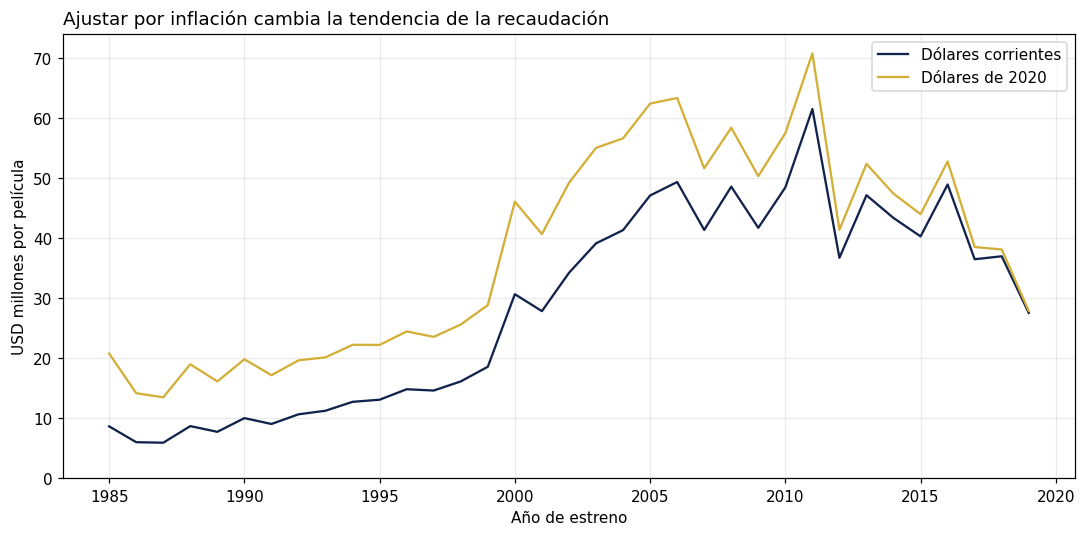

,decada,peliculas,nominal_mediana_millones,real_mediana_millones
0,1990,2000,12.87,22.13
1,2000,2000,40.41,53.42
2,2010,2000,41.67,45.79


,anio_estreno,peliculas,con_recaudacion,sin_recaudacion_pct
40,2020,25,15,40.0


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paleta usada en las clases: azul para la serie base y dorado para destacar.
AZUL_GRAFICO = '#11224D'
AZUL_CLARO_GRAFICO = '#6699CC'
DORADO_GRAFICO = '#D4AF37'
DECADA_COMPARACION_INICIO = 1990

evolucion = datos.groupby('anio_estreno').agg(
    peliculas=('id_pelicula','size'),
    con_recaudacion=('recaudacion_mundial_usd','count'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
evolucion['sin_recaudacion_pct'] = (
    100 * (1 - evolucion.con_recaudacion / evolucion.peliculas)).round(1)
evolucion['nominal_millones'] = evolucion.nominal_mediana / USD_POR_MILLON
evolucion['real_millones'] = evolucion.real_mediana / USD_POR_MILLON

serie_regular = evolucion.loc[evolucion.anio_estreno.between(
    ANIO_COBERTURA_REGULAR_INICIO, ANIO_COBERTURA_REGULAR_FIN)]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(serie_regular.anio_estreno, serie_regular.nominal_millones,
        label='Dólares corrientes', color=AZUL_GRAFICO)
ax.plot(serie_regular.anio_estreno, serie_regular.real_millones,
        label='Dólares de 2020', color=DORADO_GRAFICO)
ax.set_title('Ajustar por inflación cambia la tendencia de la recaudación', loc='left')
ax.set_xlabel('Año de estreno')
ax.set_ylabel('USD millones por película')
ax.set_ylim(0, None)
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(carpeta_salidas / '34_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

# Comparamos décadas completas para resumir la tendencia de las dos series.
decadas_completas = datos.loc[datos.anio_estreno.between(
    DECADA_COMPARACION_INICIO, ANIO_COBERTURA_REGULAR_FIN)]
resumen_decadas = decadas_completas.groupby('decada').agg(
    peliculas=('id_pelicula','size'),
    nominal_mediana=('recaudacion_mundial_usd','median'),
    real_mediana=('recaudacion_2020_usd','median')).reset_index()
resumen_decadas['nominal_mediana_millones'] = (
    resumen_decadas.nominal_mediana / USD_POR_MILLON)
resumen_decadas['real_mediana_millones'] = (
    resumen_decadas.real_mediana / USD_POR_MILLON)

print('Recaudación mediana por década completa, en USD millones:')
display(resumen_decadas[
    ['decada','peliculas','nominal_mediana_millones',
     'real_mediana_millones']].round(2))
print('Cobertura del último año, excluido del gráfico:')
display(evolucion.loc[evolucion.anio_estreno == ANIO_BASE_IPC,
                      ['anio_estreno','peliculas','con_recaudacion',
                       'sin_recaudacion_pct']])

- **En dólares corrientes:** la recaudación mediana por película pasa de USD 12,87 millones en los 90 a 40,41 millones en los 2000 y 41,67 millones en los 2010.
- **En dólares de 2020:** pasa de 22,13 a 53,42 millones y luego baja a 45,79 millones. Hubo un aumento real de los 90 a los 2000, pero no de los 2000 a los 2010; el pequeño aumento nominal de esta última comparación se explica por la inflación.
- **Alcance:** medimos la película mediana de esta base, no la recaudación total de la industria. Excluimos 2020 porque solo tiene 25 películas y al 40% le falta recaudación.

## 3.2 ¿Cuánto rinde cada tipo de película?


In [14]:
PRESUPUESTO_MIN_ANALISIS = 1_000_000
MIN_PELICULAS_COMPARABLES = 30

con_roi = datos.loc[datos.roi_salas_estimado.notna()].copy()
con_roi_hasta_2019 = con_roi.loc[
    con_roi.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN].copy()
universo_negocio = con_roi_hasta_2019.loc[
    con_roi_hasta_2019.presupuesto_usd >= PRESUPUESTO_MIN_ANALISIS].copy()
universo_negocio['roi_pct'] = 100 * universo_negocio.roi_salas_estimado

print('ROI disponibles:', len(con_roi))
print('Excluidas por 2020 incompleto:',
      len(con_roi) - len(con_roi_hasta_2019))
print('Excluidas por presupuesto menor a USD 1 millón:',
      len(con_roi_hasta_2019) - len(universo_negocio),
      f'({(len(con_roi_hasta_2019) - len(universo_negocio)) / len(con_roi_hasta_2019):.1%}'
      ' de los ROI hasta 2019)')
print('Universo principal:', len(universo_negocio),
      f'({len(universo_negocio) / len(datos):.1%} de la base depurada)')
casos_dudosos_universo = int(universo_negocio.escala_dudosa.sum())
print('Presupuestos de escala dudosa en el universo principal:',
      casos_dudosos_universo)
assert casos_dudosos_universo == 0

resumen_genero = universo_negocio.groupby('genero').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
resumen_genero['diferencia_pp'] = (
    resumen_genero.roi_medio_pct - resumen_genero.roi_mediano_pct)
print('ROI por género, en porcentaje:')
display(resumen_genero.sort_values('peliculas', ascending=False).round(1))

resumen_secuela = universo_negocio.groupby('es_secuela').agg(
    peliculas=('id_pelicula','size'),
    roi_medio_pct=('roi_pct','mean'),
    roi_mediano_pct=('roi_pct','median')).reset_index()
print('ROI por franquicia, en porcentaje:')
display(resumen_secuela.round(1))

# El efecto del filtro se observa al comparar las mismas medias por género.
media_todos = con_roi_hasta_2019.groupby(
    'genero').roi_salas_estimado.mean() * 100
media_principal = universo_negocio.groupby(
    'genero').roi_salas_estimado.mean() * 100
sensibilidad = pd.DataFrame({
    'media_con_todos_pct':media_todos,
    'media_principal_pct':media_principal
})
print('Efecto del filtro sobre algunas medias por género:')
display(sensibilidad.loc[['Aventura','Comedia','Terror']].round(1))
# Los indicadores de riesgo ya se definieron en 2.3 y se conservaron al filtrar.

ROI disponibles: 5389
Excluidas por 2020 incompleto: 8
Excluidas por presupuesto menor a USD 1 millón: 166 (3.1% de los ROI hasta 2019)
Universo principal: 5215 (68.0% de la base depurada)
Presupuestos de escala dudosa en el universo principal: 0
ROI por género, en porcentaje:
ROI por franquicia, en porcentaje:
Efecto del filtro sobre algunas medias por género:


,genero,peliculas,roi_medio_pct,roi_mediano_pct,diferencia_pp
5,Comedia,1408,1.5,-41.8,43.3
0,Acción,1378,-11.6,-37.8,26.2
6,Drama,829,2.0,-51.8,53.8
10,Policial,385,-24.6,-56.5,32.0
2,Aventura,317,-7.9,-39.3,31.4
3,Biografía,307,-13.0,-50.9,37.9
1,Animación,272,28.0,-2.8,30.7
13,Terror,236,151.6,0.2,151.4
8,Fantasía,42,-16.1,-28.6,12.4
9,Misterio,17,-6.5,-34.1,27.6


,es_secuela,peliculas,roi_medio_pct,roi_mediano_pct
0,No,4653,-1.3,-44.6
1,Si,562,39.8,-1.5


,media_con_todos_pct,media_principal_pct
genero,,
Aventura,1733.2,-7.9
Comedia,717.4,1.5
Terror,2745.0,151.6


Para las comparaciones principales usamos películas hasta 2019 con presupuesto y recaudación disponibles. El filtro de presupuesto **desde USD 1 millón** deja fuera los 31 casos de escala dudosa de 1.6; la comprobación en la celda debe mostrar **0** dentro del universo principal.

La tabla `media_con_todos_pct` sirve para mostrar cuánto cambia la media al aplicar el filtro; puede incluir presupuestos erróneos y películas pequeñas reales. Las conclusiones posteriores usan `media_principal_pct` y el universo filtrado. Este criterio también excluye éxitos reales de muy bajo presupuesto, como *Paranormal Activity*.

**Categoría adicional elegida: franquicia.** La columna `es_secuela` distingue películas de saga (`Si`) de las demás (`No`). Las 562 de saga tienen ROI medio de 39,8% y mediano de −1,5%; las 4.653 restantes tienen media de −1,3% y mediana de −44,6%. Las de saga rinden mejor en esta muestra, aunque su mediana sigue siendo negativa.

In [15]:
# Cambiamos únicamente el presupuesto de los 14 pares, sin sumar películas.
alternativas = peliculas_repetidas.loc[
    peliculas_repetidas.id_pelicula.between(ID_ADICIONAL_INICIO, ID_ADICIONAL_FIN),
    ['titulo', 'anio_estreno', 'presupuesto_usd']
].rename(columns={'presupuesto_usd':'presupuesto_alternativo'})
revision_duplicados = datos.merge(alternativas, on=['titulo','anio_estreno'],
                                  how='left')
revision_duplicados['presupuesto_revision'] = (
    revision_duplicados.presupuesto_alternativo.fillna(revision_duplicados.presupuesto_usd))
filtro_revision = (
    (revision_duplicados.presupuesto_revision >= PRESUPUESTO_MIN_ANALISIS)
    & (revision_duplicados.anio_estreno <= ANIO_COBERTURA_REGULAR_FIN)
    & revision_duplicados.recaudacion_mundial_usd.notna())
revision_roi = revision_duplicados.loc[filtro_revision].copy()
revision_roi['roi_revision'] = (
    PORCION_BOLETERIA_ESTUDIO * revision_roi.recaudacion_mundial_usd
    / (revision_roi.presupuesto_revision * (1 + MARKETING_SOBRE_PRESUPUESTO)) - 1)
print('Pares con presupuesto alternativo:', len(alternativas))
print('Porcentaje de la base revisado:', f'{len(alternativas) / len(datos):.2%}')
comparacion_duplicados = pd.DataFrame({
    'ROI mediano original (%)': universo_negocio.groupby('genero').roi_salas_estimado.median() * 100,
    'ROI mediano con alternativa (%)': revision_roi.groupby('genero').roi_revision.median() * 100
})
display(comparacion_duplicados.round(2))


Pares con presupuesto alternativo: 14
Porcentaje de la base revisado: 0.18%


,ROI mediano original (%),ROI mediano con alternativa (%)
genero,,
Acción,-37.84,-37.97
Animación,-2.78,-3.17
Aventura,-39.32,-39.32
Biografía,-50.92,-50.92
Ciencia ficción,-76.0,-76.0
Comedia,-41.78,-41.78
Drama,-51.81,-51.24
Familiar,48.23,48.23
Fantasía,-28.57,-28.57


Comparamos las medianas usando los presupuestos de las otras entradas duplicadas. Así podemos ver cuánto depende el resultado de la versión que elegimos. Esto no nos dice cuál presupuesto es verdadero.


## Comparación de la media y mediana por género


Géneros mostrados: 9 | mínimo por género: 30


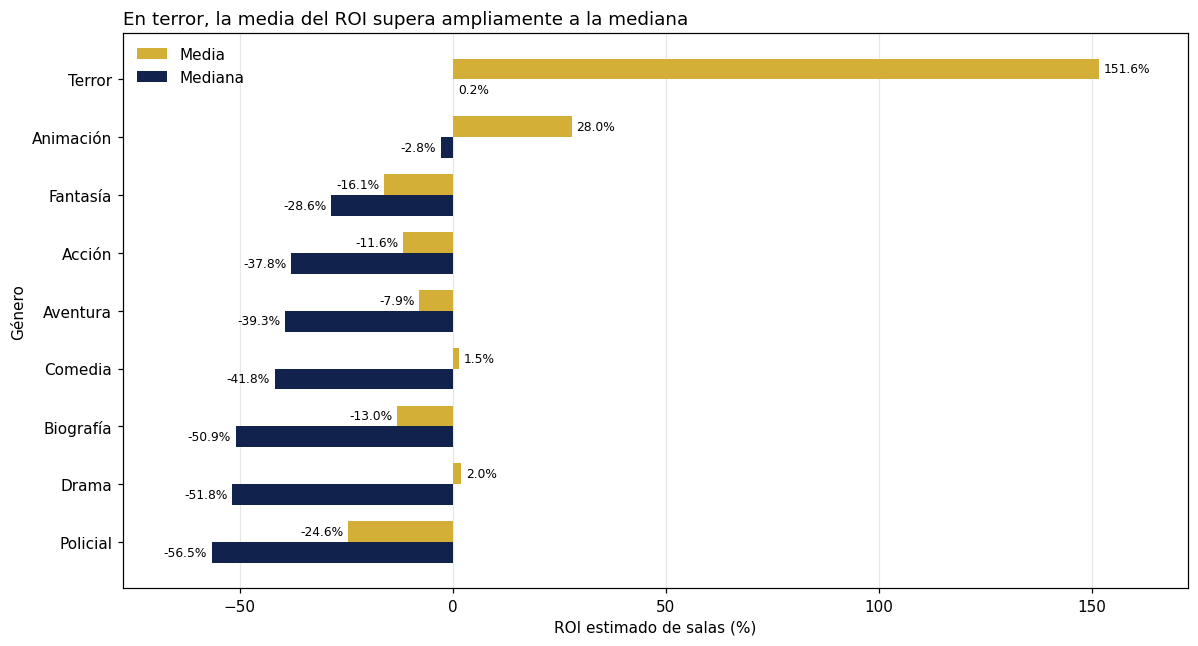

In [16]:
# Comparamos media y mediana solo en géneros con suficiente muestra.
ANCHO_BARRA = 0.36
MARGEN_EJE_PCT = 0.10
generos_comparacion = resumen_genero.loc[
    resumen_genero.peliculas >= MIN_PELICULAS_COMPARABLES].sort_values(
        'roi_mediano_pct')
posiciones = np.arange(len(generos_comparacion))

fig, ax = plt.subplots(figsize=(11, 6))
barras_media = ax.barh(
    posiciones + ANCHO_BARRA / 2, generos_comparacion.roi_medio_pct,
    height=ANCHO_BARRA, color=DORADO_GRAFICO, label='Media')
barras_mediana = ax.barh(
    posiciones - ANCHO_BARRA / 2, generos_comparacion.roi_mediano_pct,
    height=ANCHO_BARRA, color=AZUL_GRAFICO, label='Mediana')

ax.set_yticks(posiciones)
ax.set_yticklabels(generos_comparacion.genero)
roi_min = min(generos_comparacion.roi_medio_pct.min(),
              generos_comparacion.roi_mediano_pct.min())
roi_max = max(generos_comparacion.roi_medio_pct.max(),
              generos_comparacion.roi_mediano_pct.max())
margen_eje = (roi_max - roi_min) * MARGEN_EJE_PCT
ax.set_xlim(roi_min - margen_eje, roi_max + margen_eje)
ax.bar_label(barras_media, fmt='%.1f%%', padding=3, fontsize=8)
ax.bar_label(barras_mediana, fmt='%.1f%%', padding=3, fontsize=8)
ax.set_title('En terror, la media del ROI supera ampliamente a la mediana',
             loc='left')
ax.set_xlabel('ROI estimado de salas (%)')
ax.set_ylabel('Género')
ax.legend(frameon=False)
ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '38_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Géneros mostrados:', len(generos_comparacion),
      '| mínimo por género:', MIN_PELICULAS_COMPARABLES)

### Películas que elevan el promedio

In [17]:
# Elegimos las tres mayores brechas entre géneros con al menos 30 películas.
generos_brecha = (resumen_genero.loc[
    resumen_genero.peliculas >= MIN_PELICULAS_COMPARABLES]
    .nlargest(3, 'diferencia_pp'))
filas_impacto = []
peliculas_extremas = []
for genero_brecha in generos_brecha.genero:
    grupo_brecha = universo_negocio.loc[
        universo_negocio.genero == genero_brecha]
    dos_mayores = grupo_brecha.nlargest(2, 'roi_pct')
    filas_impacto.append({
        'genero': genero_brecha,
        'peliculas': len(grupo_brecha),
        'media_original_pct': grupo_brecha.roi_pct.mean(),
        'media_sin_dos_pct': grupo_brecha.drop(dos_mayores.index).roi_pct.mean(),
        'mediana_pct': grupo_brecha.roi_pct.median(),
    })
    peliculas_extremas.append(dos_mayores[
        ['genero', 'titulo', 'anio_estreno', 'presupuesto_usd',
         'recaudacion_mundial_usd', 'roi_pct']])

print('Efecto de apartar los dos ROI más altos de cada género (solo diagnóstico):')
display(pd.DataFrame(filas_impacto).round(1))
print('Películas responsables de esos valores extremos:')
display(pd.concat(peliculas_extremas).round(1))

Efecto de apartar los dos ROI más altos de cada género (solo diagnóstico):
Películas responsables de esos valores extremos:


,genero,peliculas,media_original_pct,media_sin_dos_pct,mediana_pct
0,Terror,236,151.6,126.9,0.2
1,Drama,829,2.0,-0.8,-51.8
2,Comedia,1408,1.5,-1.8,-41.8


,genero,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,roi_pct
7312,Terror,The Devil Inside,2012,1000000.0,101758490.0,3291.9
990,Terror,Saw,2004,1200000.0,103911669.0,2786.4
3475,Drama,The Lives of Others,2006,2000000.0,77356942.0,1189.3
166,Drama,Dirty Dancing,1987,6000000.0,214577242.0,1092.1
5548,Comedia,My Big Fat Greek Wedding,2002,5000000.0,368744044.0,2358.3
1302,Comedia,The Full Monty,1997,3500000.0,257938649.0,2356.6


Apartamos temporalmente el 10% de mayor ROI de cada género para medir su efecto sobre la media. Es una prueba de sensibilidad: esas películas permanecen en el análisis principal.

In [18]:
filas_cola = []
for genero_brecha in generos_brecha.genero:
    grupo_brecha = universo_negocio.loc[
        universo_negocio.genero == genero_brecha]
    cantidad_decil = int(np.ceil(len(grupo_brecha) * 0.10))
    decil_superior = grupo_brecha.nlargest(cantidad_decil, 'roi_pct')
    filas_cola.append({
        'genero': genero_brecha,
        'peliculas_apartadas': cantidad_decil,
        'media_original_pct': grupo_brecha.roi_pct.mean(),
        'media_sin_top_10_pct': grupo_brecha.drop(decil_superior.index).roi_pct.mean(),
        'mediana_pct': grupo_brecha.roi_pct.median(),
    })
display(pd.DataFrame(filas_cola).round(1))

,genero,peliculas_apartadas,media_original_pct,media_sin_top_10_pct,mediana_pct
0,Terror,24,151.6,31.3,0.2
1,Drama,83,2.0,-40.2,-51.8
2,Comedia,141,1.5,-35.3,-41.8


- **Media frente a mediana:** terror registra 151,6% frente a 0,2%; drama, 2,0% frente a −51,8%; comedia, 1,5% frente a −41,8%. La película típica rinde menos que el promedio.
- **Efecto de los éxitos:** sin el 10% de mayor ROI, solo como prueba, las medias bajan a 31,3% en terror, −40,2% en drama y −35,3% en comedia.
- **¿Error o realidad?** Los presupuestos de los casos destacados coinciden con fuentes de taquilla: terror ([*The Devil Inside*](https://www.the-numbers.com/movie/Devil-Inside-The), [*Saw*](https://www.the-numbers.com/movie/Saw-%282004%29)), drama ([*The Lives of Others*](https://www.the-numbers.com/movie/Leben-der-Anderen-Das), [*Dirty Dancing*](https://www.boxofficemojo.com/title/tt0092890/)) y comedia ([*My Big Fat Greek Wedding*](https://www.the-numbers.com/movie/My-Big-Fat-Greek-Wedding), [*The Full Monty*](https://www.the-numbers.com/movie/Full-Monty-The)). En estos ejemplos no aparece un error de escala ×1.000; son éxitos reales que elevan la media.

In [19]:
print('Películas con mayor ROI en el universo principal:')
display(universo_negocio.sort_values('roi_salas_estimado', ascending=False)
        [['titulo','genero','presupuesto_usd',
          'recaudacion_mundial_usd','roi_pct']].head(8).round(1))

# Contrastamos importes pequeños: un múltiplo enorme no prueba un error.
casos_a_revisar = datos.loc[datos.titulo.isin(
    ['Platoon','Paranormal Activity','The Devil Inside']),
    ['titulo','anio_estreno','presupuesto_usd',
     'recaudacion_mundial_usd','multiplo_boleteria','escala_dudosa']]
print('Casos que ayudan a distinguir errores de éxitos reales:')
display(casos_a_revisar.round(1))

Películas con mayor ROI en el universo principal:
Casos que ayudan a distinguir errores de éxitos reales:


,titulo,genero,presupuesto_usd,recaudacion_mundial_usd,roi_pct
7312,The Devil Inside,Terror,1000000.0,101758490.0,3291.9
990,Saw,Terror,1200000.0,103911669.0,2786.4
7397,E.T. the Extra-Terrestrial,Familiar,10500000.0,792910554.0,2417.2
5548,My Big Fat Greek Wedding,Comedia,5000000.0,368744044.0,2358.3
1302,The Full Monty,Comedia,3500000.0,257938649.0,2356.6
2217,Insidious,Terror,1500000.0,99557032.0,2112.4
4566,Unfriended,Terror,1000000.0,62882090.0,1996.1
217,Paranormal Activity 2,Terror,3000000.0,177512032.0,1872.4


,titulo,anio_estreno,presupuesto_usd,recaudacion_mundial_usd,multiplo_boleteria,escala_dudosa
263,Platoon,1986,6000.0,138545632.0,23090.9,True
5886,Paranormal Activity,2007,15000.0,193355800.0,12890.4,True
7312,The Devil Inside,2012,1000000.0,101758490.0,101.8,False


- **Error fuera del universo principal:** *Platoon* figura con USD 6.000 en la base, frente a [USD 6 millones publicados](https://www.the-numbers.com/movie/Platoon); el filtro la excluye.
- **Presupuesto mínimo real:** [Paramount informa USD 15.000](https://ir.paramount.com/news-releases/news-release-details/paramount-pictures-paranormal-activity-soars-past-100-million/) para *Paranormal Activity*, también excluida por el filtro.
- **Éxito dentro del universo:** *The Devil Inside* figura con USD 1 millón, de acuerdo con [su presupuesto publicado](https://www.the-numbers.com/movie/Devil-Inside-The). Un ROI muy alto no prueba por sí solo un error de carga.

Películas con puntaje IMDb y ROI: 5198
Correlación IMDb–ROI: 0.173


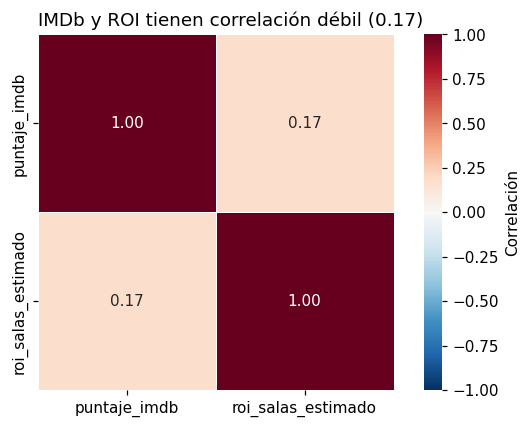

In [20]:
# Correlación de Pearson en el mismo universo usado para comparar retornos.
variables_correlacion = ['puntaje_imdb','roi_salas_estimado']
matriz_correlacion = universo_negocio[variables_correlacion].corr()
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(matriz_correlacion, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            cbar_kws={'label':'Correlación'}, ax=ax)
correlacion_imdb_roi = matriz_correlacion.loc[
    'puntaje_imdb','roi_salas_estimado']
ax.set_title(f'IMDb y ROI tienen correlación débil ({correlacion_imdb_roi:.2f})',
             loc='left')
fig.tight_layout()
fig.savefig(carpeta_salidas / '42_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Películas con puntaje IMDb y ROI:',
      universo_negocio[variables_correlacion].dropna().shape[0])
print('Correlación IMDb–ROI:', round(correlacion_imdb_roi, 3))

La relación entre IMDb y retorno es débil. Una buena puntuación no asegura recuperar la inversión.

Además, el puntaje se conoce después del estreno. No lo podemos usar para elegir qué película financiar antes de hacerla.


## 3.3 ¿Dónde está el riesgo?


In [21]:
FRACCION_PEOR_DECIL = 0.10

def retorno_peor_decil(serie):
    limite = serie.quantile(FRACCION_PEOR_DECIL)
    return serie.loc[serie <= limite].mean()

def tabla_riesgo(columna):
    tabla = universo_negocio.groupby(columna).agg(
        peliculas=('id_pelicula','size'),
        roi_mediano_pct=('roi_pct','median'),
        fracaso_pct=('fracaso_2_5x','mean'),
        perdida_roi_pct=('perdida_roi','mean'),
        roi_peor_decil_pct=('roi_pct',retorno_peor_decil)).reset_index()
    tabla['fracaso_pct'] = 100 * tabla.fracaso_pct
    tabla['perdida_roi_pct'] *= 100
    return tabla.sort_values('peliculas', ascending=False)

riesgo_genero = tabla_riesgo('genero')
riesgo_secuela = tabla_riesgo('es_secuela')
print('Riesgo por género: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo')
display(riesgo_genero.round(1))
print('Riesgo por franquicia: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo')
display(riesgo_secuela.round(1))

# Aplicamos el mismo criterio de dominancia a las dos categorías de franquicia.
secuela_si = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'Si'].iloc[0]
secuela_no = riesgo_secuela.loc[
    riesgo_secuela.es_secuela == 'No'].iloc[0]
print('Dominancia por franquicia:')
if (secuela_si.roi_mediano_pct > secuela_no.roi_mediano_pct
        and secuela_si.fracaso_pct < secuela_no.fracaso_pct):
    print('Las secuelas dominan en ROI mediano y en no llegar a 2,5×.')
else:
    print('No hay dominancia de secuelas en ROI mediano y regla de 2,5×.')

# Dominancia compara mediana y fracaso; la propia fila no se domina a sí misma.
comparables = riesgo_genero.loc[
    riesgo_genero.peliculas >= MIN_PELICULAS_COMPARABLES].reset_index(drop=True).copy()
dominador_ejemplo = []
for i in range(len(comparables)):
    actual = comparables.iloc[i]
    mejor_retorno = comparables.roi_mediano_pct >= actual.roi_mediano_pct
    menor_fracaso = comparables.fracaso_pct <= actual.fracaso_pct
    ventaja_estricta = ((comparables.roi_mediano_pct > actual.roi_mediano_pct)
                        | (comparables.fracaso_pct < actual.fracaso_pct))
    nombres = comparables.loc[mejor_retorno & menor_fracaso & ventaja_estricta,
                             'genero']
    if len(nombres) > 0:
        dominador_ejemplo.append(nombres.iloc[0])
    else:
        dominador_ejemplo.append('Ninguno')

comparables['dominador_ejemplo'] = dominador_ejemplo
print('Dominancia entre géneros con al menos', MIN_PELICULAS_COMPARABLES,
      'películas:')
display(comparables.sort_values('roi_mediano_pct', ascending=False)
        [['genero','peliculas','roi_mediano_pct','fracaso_pct',
          'roi_peor_decil_pct','dominador_ejemplo']].round(1))
print('Géneros no dominados:',
      ', '.join(list(comparables.loc[
          comparables.dominador_ejemplo == 'Ninguno', 'genero'])))

Riesgo por género: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo
Riesgo por franquicia: fracaso_pct = no llegar a 2,5×; perdida_roi_pct = ROI negativo
Dominancia por franquicia:
Las secuelas dominan en ROI mediano y en no llegar a 2,5×.
Dominancia entre géneros con al menos 30 películas:
Géneros no dominados: Animación, Terror


,genero,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
5,Comedia,1408,-41.8,62.9,70.3,-95.7
0,Acción,1378,-37.8,62.8,69.8,-93.2
6,Drama,829,-51.8,65.0,71.2,-98.0
10,Policial,385,-56.5,71.2,76.6,-97.3
2,Aventura,317,-39.3,61.5,69.4,-96.3
3,Biografía,307,-50.9,68.4,74.9,-95.6
1,Animación,272,-2.8,41.9,51.8,-89.1
13,Terror,236,0.2,42.8,50.0,-92.8
8,Fantasía,42,-28.6,57.1,66.7,-96.1
9,Misterio,17,-34.1,58.8,58.8,-99.3


,es_secuela,peliculas,roi_mediano_pct,fracaso_pct,perdida_roi_pct,roi_peor_decil_pct
0,No,4653,-44.6,64.5,71.3,-96.2
1,Si,562,-1.5,41.1,50.2,-86.6


,genero,peliculas,roi_mediano_pct,fracaso_pct,roi_peor_decil_pct,dominador_ejemplo
7,Terror,236,0.2,42.8,-92.8,Ninguno
6,Animación,272,-2.8,41.9,-89.1,Ninguno
8,Fantasía,42,-28.6,57.1,-96.1,Animación
1,Acción,1378,-37.8,62.8,-93.2,Animación
4,Aventura,317,-39.3,61.5,-96.3,Animación
0,Comedia,1408,-41.8,62.9,-95.7,Acción
5,Biografía,307,-50.9,68.4,-95.6,Comedia
2,Drama,829,-51.8,65.0,-98.0,Comedia
3,Policial,385,-56.5,71.2,-97.3,Comedia


### Riesgo y retorno mediano por género

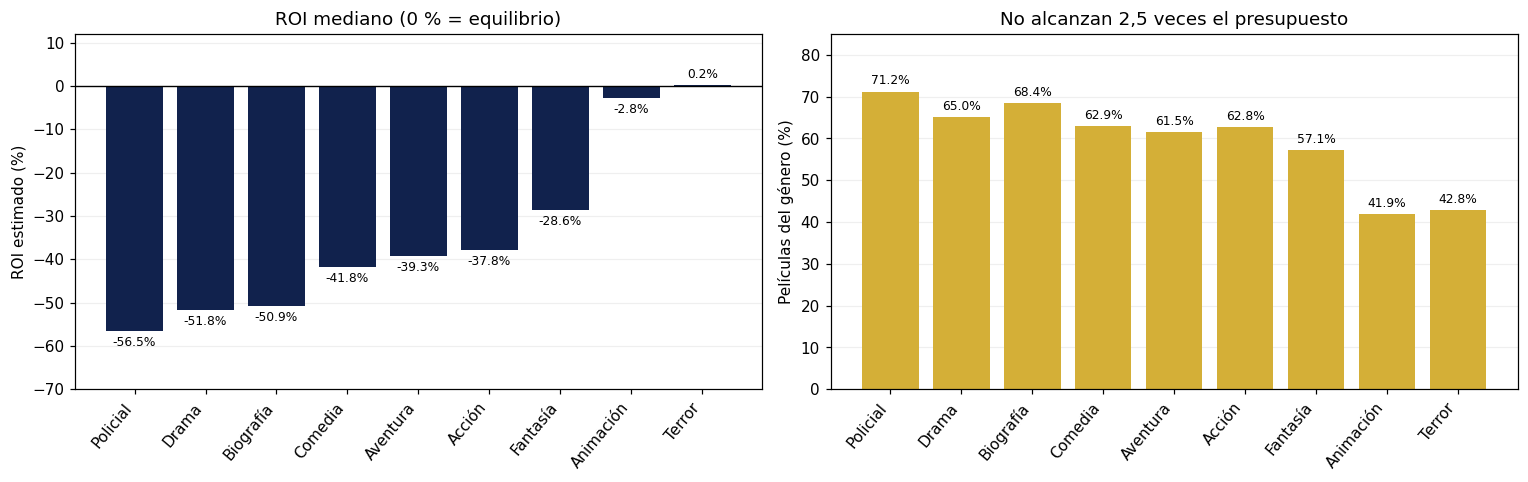

In [22]:
# Mismos géneros comparables usados en la tabla de dominancia.
riesgo_barras = comparables.sort_values('roi_mediano_pct').reset_index(drop=True)
posiciones_riesgo = np.arange(len(riesgo_barras))
etiquetas_riesgo = riesgo_barras.genero.tolist()

fig, (ax_retorno, ax_fracaso) = plt.subplots(
    1, 2, figsize=(14, 4.5))
barras_retorno = ax_retorno.bar(
    posiciones_riesgo, riesgo_barras.roi_mediano_pct, color=AZUL_GRAFICO)
ax_retorno.axhline(0, color='black', linewidth=0.9)
ax_retorno.set_ylim(-70, 12)
ax_retorno.bar_label(barras_retorno, fmt='%.1f%%', padding=3, fontsize=8)
ax_retorno.set_title('ROI mediano (0 % = equilibrio)')
ax_retorno.set_ylabel('ROI estimado (%)')

barras_fracaso = ax_fracaso.bar(
    posiciones_riesgo, riesgo_barras.fracaso_pct, color=DORADO_GRAFICO)
ax_fracaso.set_ylim(0, 85)
ax_fracaso.bar_label(barras_fracaso, fmt='%.1f%%', padding=3, fontsize=8)
ax_fracaso.set_title('No alcanzan 2,5 veces el presupuesto')
ax_fracaso.set_ylabel('Películas del género (%)')

for eje in (ax_retorno, ax_fracaso):
    eje.set_xticks(posiciones_riesgo, etiquetas_riesgo, rotation=50, ha='right')
    eje.grid(axis='y', alpha=0.2)
    eje.set_axisbelow(True)

fig.tight_layout()
fig.savefig(carpeta_salidas / '3_3_riesgo_por_genero.png',
            dpi=150, bbox_inches='tight')
plt.show()

- **Gráficos:** el eje horizontal muestra los géneros con al menos 30 películas (sus tamaños están en la tabla anterior). A la izquierda, las barras bajo 0% indican ROI mediano negativo; a la derecha, barras más altas indican que más películas no llegan a 2,5×.
- `fracaso_pct` es el porcentaje que **no llega a 2,5×**; `perdida_roi_pct` es el porcentaje con **ROI negativo**. Son los dos indicadores creados en 2.3 y pueden dar cifras distintas.
- `roi_peor_decil_pct` es el ROI promedio del 10% con peor resultado. Un género domina a otro si tiene a la vez mayor ROI mediano y menos películas bajo 2,5×.
- **Géneros:** terror tiene ROI mediano de 0,2% y 42,8% de películas bajo 2,5×. Animación tiene −2,8% y 41,9%. Terror gana un poco en retorno y animación un poco en riesgo: ninguno supera al otro en ambas medidas.
- **Franquicias:** las secuelas tienen mejor ROI mediano y menos casos bajo 2,5× que las no secuelas. Aun así, su ROI mediano es −1,5%; no equivale a una ganancia asegurada.
- **Cuánto se puede perder:** entre el 10% de peores películas, el ROI promedio es −92,8% en terror y −89,1% en animación. Incluso los grupos mejor posicionados pueden perder casi todo el costo estimado en algunos proyectos; por eso conviene diversificar.

## 4.1 Evolución nominal y real de la recaudación


In [23]:
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

pio.templates.default = 'plotly_white'
GRIS_GRAFICO = '#BBBBBB'

figura_evolucion = go.Figure()
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.nominal_millones,
    mode='lines', name='Dólares corrientes',
    line={'color':AZUL_GRAFICO,'width':2}))
figura_evolucion.add_trace(go.Scatter(
    x=serie_regular.anio_estreno, y=serie_regular.real_millones,
    mode='lines', name='Dólares de 2020',
    line={'color':DORADO_GRAFICO,'width':2}))
figura_evolucion.update_layout(
    title='La recaudación nominal y real muestran trayectorias distintas',
    xaxis_title='Año de estreno',
    yaxis_title='Recaudación mediana por película (USD millones)',
    hovermode='x unified', height=460)
figura_evolucion.update_yaxes(rangemode='tozero')
figura_evolucion.write_html(carpeta_salidas / 'evolucion_interactiva.html', include_plotlyjs='cdn')
figura_evolucion.show()

print('Años mostrados:', len(serie_regular),
      '| desde', serie_regular.anio_estreno.min(),
      'hasta', serie_regular.anio_estreno.max())

Años mostrados: 35 | desde 1985 hasta 2019


Grafico interactivo

La serie nominal sugiere crecimiento sostenido. En dólares de 2020, la mediana sube hasta los 2000 y baja en los 2010; por eso no conviene interpretar el aumento nominal como crecimiento real continuo.

## 4.2 Media, mediana y efecto de los extremos


In [24]:
# Revisamos qué películas entran en cada comparación.
excluidas_presupuesto = con_roi_hasta_2019[
    con_roi_hasta_2019['presupuesto_usd'] < PRESUPUESTO_MIN_ANALISIS]

filas_muestras = []
for nombre, muestra in [
    ('Con ROI hasta 2019, antes del filtro', con_roi_hasta_2019),
    ('Excluidas por presupuesto menor a USD 1 millón', excluidas_presupuesto),
    ('Universo principal del análisis', universo_negocio)
]:
    filas_muestras.append({
        'muestra': nombre,
        'peliculas': len(muestra),
        'media_multiplo': muestra['multiplo_boleteria'].mean(),
        'mediana_multiplo': muestra['multiplo_boleteria'].median(),
        'con_escala_dudosa': muestra['escala_dudosa'].sum()
    })
revision_muestras = pd.DataFrame(filas_muestras)
display(revision_muestras.round(2))

display(excluidas_presupuesto.nlargest(8, 'multiplo_boleteria')[
    ['titulo', 'presupuesto_usd', 'recaudacion_mundial_usd',
     'multiplo_boleteria', 'escala_dudosa']].round(2))


,muestra,peliculas,media_multiplo,mediana_multiplo,con_escala_dudosa
0,"Con ROI hasta 2019, antes del filtro",5381,26.58,1.86,30
1,Excluidas por presupuesto menor a USD 1 millón,166,764.44,12.52,30
2,Universo principal del análisis,5215,3.09,1.80,0


,titulo,presupuesto_usd,recaudacion_mundial_usd,multiplo_boleteria,escala_dudosa
263,Platoon,6000.0,138545632.0,23090.94,True
4409,Bean,18000.0,251212670.0,13956.26,True
5886,Paranormal Activity,15000.0,193355800.0,12890.39,True
1876,"Good Night, and Good Luck.",7000.0,54641191.0,7805.88,True
3318,Sex and the City,65000.0,418765519.0,6442.55,True
447,Guardians of the Galaxy Vol. 2,200000.0,863756051.0,4318.78,True
1645,The Blair Witch Project,60000.0,248639099.0,4143.98,True
282,21 & Over,13000.0,48065672.0,3697.36,True


El filtro de USD 1 millón aparta 166 películas. Entre ellas están Paranormal Activity y The Blair Witch Project, que tuvieron un costo muy bajo y mucha recaudación. También aparecen presupuestos dudosos, como el de Platoon.

Por eso la media de toda la base es mucho mayor, pero no conviene usarla sin revisar esos presupuestos. La marca de escala dudosa señala casos para investigar, no demuestra que todos sean errores.

Esta tabla es una comparación de muestras. El análisis y la propuesta siguen usando el universo principal; no agregamos películas para conseguir un promedio más alto.


Películas del universo principal: 5215
Múltiplo positivo mostrado: 5215 | múltiplo cero excluido del gráfico log: 0
Múltiplo promedio y mediano: 3.09 y 1.8
ROI medio y mediano estimado (%): 3.2 y -39.9


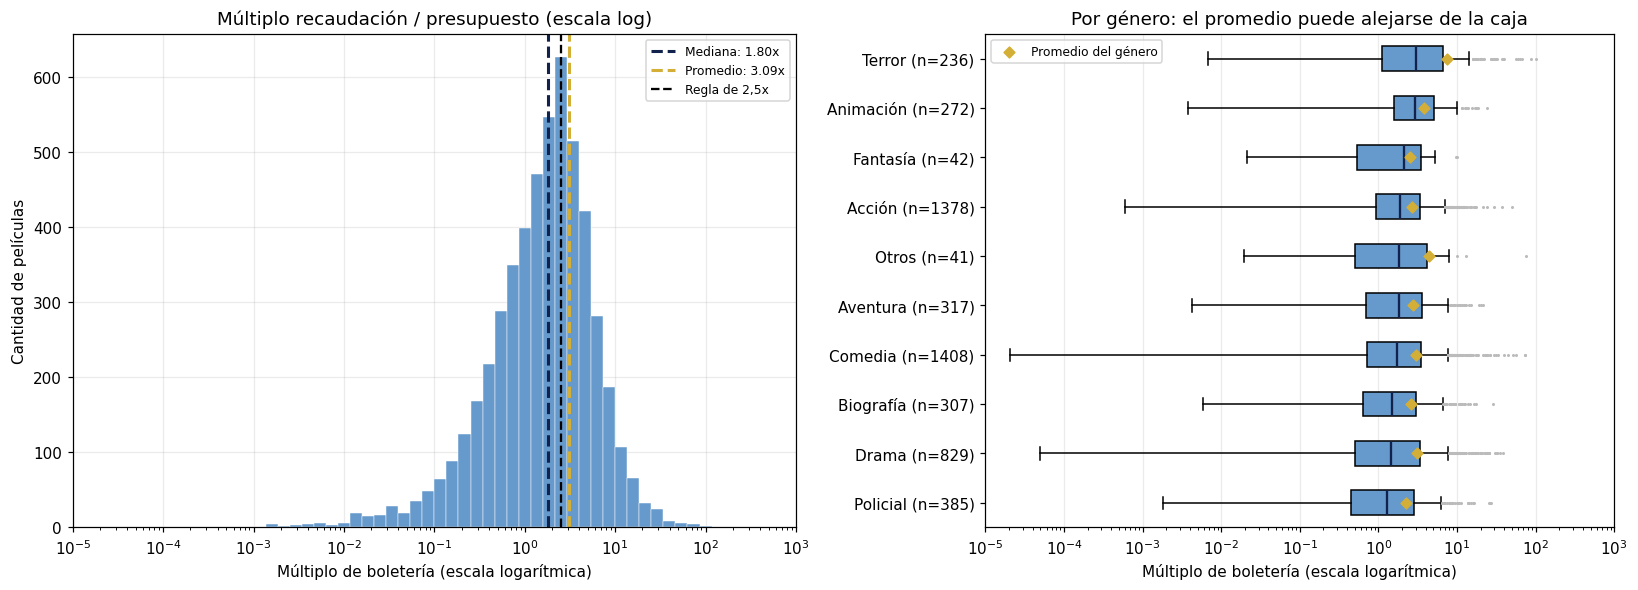

In [25]:
CANTIDAD_BINS_MULTIPLO = 60

# La escala logarítmica solo admite múltiplos estrictamente positivos.
multiplo_visual = universo_negocio.loc[
    universo_negocio.multiplo_boleteria > 0,
    ['genero', 'multiplo_boleteria']
].copy()
multiplo_visual['multiplo_boleteria'] = (
    multiplo_visual.multiplo_boleteria.astype(float))
mediana_multiplo = multiplo_visual.multiplo_boleteria.median()
media_multiplo = multiplo_visual.multiplo_boleteria.mean()
limite_min = 10 ** np.floor(np.log10(multiplo_visual.multiplo_boleteria.min()))
limite_max = 10 ** np.ceil(np.log10(multiplo_visual.multiplo_boleteria.max()))
bins_multiplo = np.logspace(
    np.log10(limite_min), np.log10(limite_max),
    CANTIDAD_BINS_MULTIPLO + 1)

# Agrupamos los géneros con menos de 30 películas en "Otros".
generos_box = multiplo_visual.genero.value_counts()
generos_box = generos_box.loc[
    generos_box >= MIN_PELICULAS_COMPARABLES].index
multiplo_visual['grupo_genero'] = multiplo_visual.genero.where(
    multiplo_visual.genero.isin(generos_box), 'Otros')
orden_generos = (multiplo_visual.groupby('grupo_genero')
                 .multiplo_boleteria.median()
                 .sort_values(ascending=False).index.tolist())
datos_por_genero = [
    multiplo_visual.loc[
        multiplo_visual.grupo_genero == genero,
        'multiplo_boleteria'].to_numpy()
    for genero in orden_generos
]
medias_genero = [valores.mean() for valores in datos_por_genero]

fig, (ax_hist, ax_box) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios':[1.15, 1]})

ax_hist.hist(multiplo_visual.multiplo_boleteria, bins=bins_multiplo,
             color=AZUL_CLARO_GRAFICO, edgecolor='white', linewidth=0.3)
ax_hist.axvline(mediana_multiplo, color=AZUL_GRAFICO, linestyle='--',
                linewidth=2, label=f'Mediana: {mediana_multiplo:.2f}x')
ax_hist.axvline(media_multiplo, color=DORADO_GRAFICO, linestyle='--',
                linewidth=2, label=f'Promedio: {media_multiplo:.2f}x')
ax_hist.axvline(UMBRAL_RECUPERO, color='black', linestyle='--',
                linewidth=1.5, label='Regla de 2,5x')
ax_hist.set_xscale('log')
ax_hist.set_xlim(limite_min, limite_max)
ax_hist.set_title('Múltiplo recaudación / presupuesto (escala log)')
ax_hist.set_xlabel('Múltiplo de boletería (escala logarítmica)')
ax_hist.set_ylabel('Cantidad de películas')
ax_hist.legend(fontsize=8)
ax_hist.grid(alpha=0.25)
ax_hist.set_axisbelow(True)

cajas = ax_box.boxplot(
    datos_por_genero, vert=False, patch_artist=True,
    flierprops={'marker':'.', 'markersize':2, 'markeredgecolor':GRIS_GRAFICO},
    medianprops={'color':AZUL_GRAFICO, 'linewidth':1.5})
ax_box.set_yticks(np.arange(1, len(orden_generos) + 1))
etiquetas_generos = []
for genero in orden_generos:
    cantidad = (multiplo_visual['grupo_genero'] == genero).sum()
    etiquetas_generos.append(f'{genero} (n={cantidad})')
ax_box.set_yticklabels(etiquetas_generos)
for caja in cajas['boxes']:
    caja.set_facecolor(AZUL_CLARO_GRAFICO)
ax_box.scatter(medias_genero, np.arange(1, len(orden_generos) + 1),
               marker='D', s=25, color=DORADO_GRAFICO,
               zorder=3, label='Promedio del género')
ax_box.set_xscale('log')
ax_box.set_xlim(limite_min, limite_max)
ax_box.invert_yaxis()
ax_box.set_title('Por género: el promedio puede alejarse de la caja')
ax_box.set_xlabel('Múltiplo de boletería (escala logarítmica)')
ax_box.legend(fontsize=8)
ax_box.grid(axis='x', alpha=0.25)
ax_box.set_axisbelow(True)

fig.tight_layout()
fig.savefig(carpeta_salidas / '52_grafico.png', dpi=150, bbox_inches='tight')
plt.show()

print('Películas del universo principal:', len(universo_negocio))
print('Múltiplo positivo mostrado:', len(multiplo_visual),
      '| múltiplo cero excluido del gráfico log:',
      len(universo_negocio) - len(multiplo_visual))
print('Múltiplo promedio y mediano:',
      round(media_multiplo, 2), 'y', round(mediana_multiplo, 2))
print('ROI medio y mediano estimado (%):',
      round(universo_negocio.roi_pct.mean(), 1), 'y',
      round(universo_negocio.roi_pct.median(), 1))

En la muestra principal la media da 3,09x y la mediana 1,80x. La media es aproximadamente un 72% mayor. El efecto de los extremos ya existe, aunque el eje logarítmico hace que las dos líneas parezcan cercanas.

La línea de 2,5x es una regla de recuperación, no el valor al que debería acercarse la mediana. Acá el promedio supera esa regla, mientras que la película mediana queda por debajo. Eso ya muestra por qué mirar solamente el promedio puede ser optimista.

El boxplot separa los géneros. En terror la diferencia es más grande: media de 7,55x frente a mediana de 3,00x. En los otros géneros no tiene por qué ser igual.


In [26]:
# Apartamos temporalmente el 1%, 5% y 10% de mayor múltiplo.
# No borramos ni cambiamos las películas del análisis principal.
multiplos_ordenados = universo_negocio['multiplo_boleteria'].sort_values(ascending=False)
filas_extremos = []
for porcentaje in [0, 1, 5, 10]:
    cantidad = int(np.ceil(len(multiplos_ordenados) * porcentaje / 100))
    sin_extremos = multiplos_ordenados.iloc[cantidad:]
    filas_extremos.append({
        'porcentaje_superior_apartado': porcentaje,
        'peliculas_apartadas': cantidad,
        'peliculas_restantes': len(sin_extremos),
        'media_multiplo': sin_extremos.mean(),
        'mediana_multiplo': sin_extremos.median()
    })
revision_extremos = pd.DataFrame(filas_extremos)
media_original = revision_extremos['media_multiplo'].iloc[0]
mediana_original = revision_extremos['mediana_multiplo'].iloc[0]
revision_extremos['caida_media_pct'] = (
    1 - revision_extremos['media_multiplo'] / media_original) * 100
revision_extremos['caida_mediana_pct'] = (
    1 - revision_extremos['mediana_multiplo'] / mediana_original) * 100
display(revision_extremos.round(2))


,porcentaje_superior_apartado,peliculas_apartadas,peliculas_restantes,media_multiplo,mediana_multiplo,caida_media_pct,caida_mediana_pct
0,0,0,5215,3.09,1.80,0.00,0.00
1,1,53,5162,2.73,1.77,11.78,1.61
2,5,261,4954,2.26,1.68,26.82,7.02
3,10,522,4693,1.95,1.54,37.04,14.79


Al apartar solo el 1% de mayor múltiplo, la media baja de 3,09x a 2,73x. La mediana cambia mucho menos: de 1,80x a 1,77x.

Esto permite ver el efecto de unas pocas películas sin depender de cómo se dibuja el histograma. Es una prueba de sensibilidad: los éxitos reales siguen en los datos y no se eliminan del análisis.


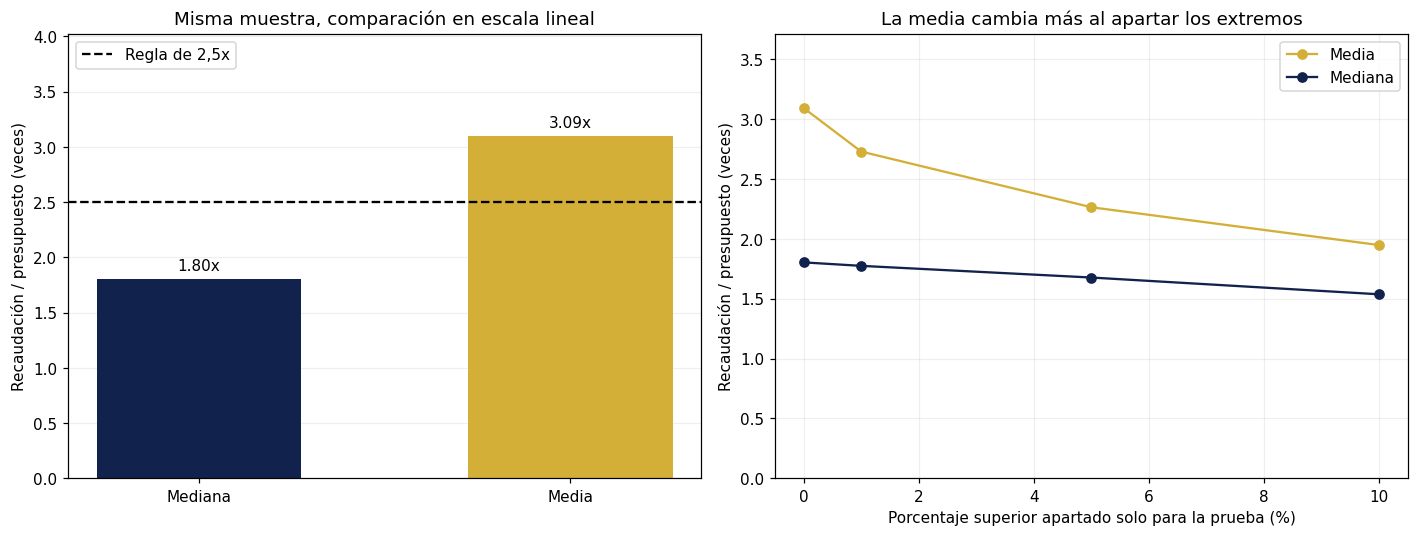

In [27]:
# La escala lineal sirve acá para comparar directamente las medidas resumidas.
# El histograma y los boxplots anteriores mantienen sus ejes logarítmicos.
fig_revision, (ax_centro, ax_extremos) = plt.subplots(1, 2, figsize=(13, 5))
barras = ax_centro.bar(
    ['Mediana', 'Media'], [mediana_original, media_original],
    color=[AZUL_GRAFICO, DORADO_GRAFICO], width=0.55)
ax_centro.bar_label(barras, fmt='%.2fx', padding=4)
ax_centro.axhline(UMBRAL_RECUPERO, color='black', linestyle='--',
                  label='Regla de 2,5x')
ax_centro.set_ylim(0, media_original * 1.3)
ax_centro.set_ylabel('Recaudación / presupuesto (veces)')
ax_centro.set_title('Misma muestra, comparación en escala lineal')
ax_centro.legend(loc='upper left')
ax_centro.grid(axis='y', alpha=0.2)
ax_centro.set_axisbelow(True)

ax_extremos.plot(revision_extremos['porcentaje_superior_apartado'],
                 revision_extremos['media_multiplo'], marker='o',
                 color=DORADO_GRAFICO, label='Media')
ax_extremos.plot(revision_extremos['porcentaje_superior_apartado'],
                 revision_extremos['mediana_multiplo'], marker='o',
                 color=AZUL_GRAFICO, label='Mediana')
ax_extremos.set_xlabel('Porcentaje superior apartado solo para la prueba (%)')
ax_extremos.set_ylabel('Recaudación / presupuesto (veces)')
ax_extremos.set_title('La media cambia más al apartar los extremos')
ax_extremos.set_ylim(0, media_original * 1.2)
ax_extremos.legend()
ax_extremos.grid(alpha=0.2)
fig_revision.tight_layout()
fig_revision.savefig(carpeta_salidas / 'diagnostico_media_mediana.png',
                      dpi=150, bbox_inches='tight')
plt.show()


Para describir a la película típica conviene usar la mediana. La media también aporta información sobre los éxitos grandes, pero hay que mostrarla junto con la mediana, la proporción de fracasos y el tamaño de la muestra.

La solución no es mover las líneas para que la mediana quede cerca de 2,5x. Es explicar qué películas entran en la comparación y mostrar cuánto cambian las medidas cuando apartamos temporalmente los extremos.


## 4.3 Retorno mediano por género


In [28]:
generos_grafico = comparables.sort_values('roi_mediano_pct')

figura_generos = px.bar(
    generos_grafico, x='roi_mediano_pct', y='genero',
    orientation='h', text='roi_mediano_pct',
    hover_data=['peliculas','fracaso_pct','roi_peor_decil_pct'],
    color_discrete_sequence=[AZUL_GRAFICO],
    labels={'roi_mediano_pct':'ROI mediano estimado (%)',
            'genero':'Género',
            'peliculas':'Películas',
            'fracaso_pct':'Fracaso según 2,5× (%)',
            'roi_peor_decil_pct':'ROI medio del peor decil (%)'},
    title='Terror y animación encabezan el ROI mediano entre géneros comparables')
figura_generos.update_traces(texttemplate='%{text:.1f}%',
                             textposition='outside', cliponaxis=False)
limite_izquierdo = min(-60, generos_grafico.roi_mediano_pct.min() - 7)
limite_derecho = max(5, generos_grafico.roi_mediano_pct.max() + 5)
figura_generos.update_xaxes(range=[limite_izquierdo, limite_derecho])
figura_generos.update_layout(height=530,
                             margin={'l':145,'r':90,'t':80,'b':60})
figura_generos.write_html(carpeta_salidas / 'generos_interactivo.html', include_plotlyjs='cdn')
figura_generos.show()

print('Géneros mostrados:', len(generos_grafico),
      '| mínimo por género:', MIN_PELICULAS_COMPARABLES)

Géneros mostrados: 9 | mínimo por género: 30


Grafico interactivo

Terror y animación quedan entre los géneros con mejor retorno mediano. Esto no significa que sean seguros: también tienen películas con pérdidas. En el gráfico se puede consultar cuántos casos tiene cada grupo.


## 4.4 Presupuesto frente a recaudación


In [29]:
# La escala logarítmica requiere importes estrictamente positivos.
dispersion = universo_negocio.loc[
    (universo_negocio.presupuesto_2020_usd > 0)
    & (universo_negocio.recaudacion_2020_usd > 0)].copy()
dispersion['presupuesto_millones'] = (
    dispersion.presupuesto_2020_usd / USD_POR_MILLON)
dispersion['recaudacion_millones'] = (
    dispersion.recaudacion_2020_usd / USD_POR_MILLON)

dispersion['resultado_2_5x'] = dispersion.fracaso_2_5x.map({
    True:'Debajo de 2,5×', False:'Al menos 2,5×'})
figura_dispersion = px.scatter(
    dispersion, x='presupuesto_millones', y='recaudacion_millones',
    color='resultado_2_5x', hover_name='titulo',
    hover_data={'anio_estreno':True, 'genero':True,
                'presupuesto_millones':':.2f',
                'recaudacion_millones':':.2f',
                'multiplo_boleteria':':.1f',
                'resultado_2_5x':False},
    color_discrete_map={'Debajo de 2,5×':GRIS_GRAFICO,
                        'Al menos 2,5×':AZUL_GRAFICO},
    opacity=0.4, log_x=True, log_y=True,
    labels={'presupuesto_millones':'Presupuesto (USD millones de 2020)',
            'recaudacion_millones':'Recaudación mundial (USD millones de 2020)',
            'multiplo_boleteria':'Recaudación / presupuesto'},
    title='Presupuestos similares tienen recaudaciones muy distintas')
presupuesto_min = dispersion.presupuesto_millones.min()
presupuesto_max = dispersion.presupuesto_millones.max()
figura_dispersion.add_trace(go.Scatter(
    x=[presupuesto_min, presupuesto_max],
    y=[UMBRAL_RECUPERO * presupuesto_min,
       UMBRAL_RECUPERO * presupuesto_max],
    mode='lines', name='Umbral de 2,5×',
    line={'color':DORADO_GRAFICO, 'dash':'dash', 'width':2},
    hovertemplate='Recaudación = 2,5 × presupuesto<extra></extra>'))
figura_dispersion.update_layout(
    height=520, legend_title_text='Regla de 2,5×',
    margin={'l':80, 'r':70, 't':80, 'b':70})
figura_dispersion.write_html(
    carpeta_salidas / 'presupuesto_recaudacion_interactivo.html',
    include_plotlyjs='cdn')
figura_dispersion.show()

print('Películas mostradas:', len(dispersion),
      '| excluidas por importe cero para la escala log:',
      len(universo_negocio) - len(dispersion))

Películas mostradas: 5215 | excluidas por importe cero para la escala log: 0


Grafico interactivo

Películas con presupuestos parecidos tienen recaudaciones muy distintas. El gráfico interactivo permite ver cada título y sus importes; ambos ejes usan escala logarítmica para comparar montos muy diferentes. La línea marca 2,5 veces el presupuesto y los colores usan `fracaso_2_5x` de 2.3. Estar por encima cumple esa regla, pero no garantiza ROI positivo con los costos supuestos.

# Etapa 5: propuesta de inversión

## 5.1 Definir los grupos

In [30]:
CORTES_PRESUPUESTO_M = [0, 10, 30, 70, np.inf]
NOMBRES_TRAMOS = ['Hasta 10', '10-30', '30-70', 'Más de 70']

portafolio_base = universo_negocio.copy()
portafolio_base['presupuesto_millones'] = (
    portafolio_base.presupuesto_2020_usd / USD_POR_MILLON)
portafolio_base['tramo_presupuesto'] = pd.cut(
    portafolio_base.presupuesto_millones,
    bins=CORTES_PRESUPUESTO_M, labels=NOMBRES_TRAMOS)

# Verificamos que los tramos propuestos tengan casos suficientes.
resumen_tramos = portafolio_base.groupby(
    'tramo_presupuesto', observed=True).agg(
        peliculas=('id_pelicula','size'),
        presupuesto_mediano_m=('presupuesto_millones','median')).reset_index()
print('Películas y presupuesto mediano por tramo:')
display(resumen_tramos.round(1))

# Cada fila define un grupo observable; la asignación se decide en 5.2.
grupos_elegidos = pd.DataFrame([
    {'grupo':'Animación, más de 70 M, secuela',
     'genero':'Animación', 'tramo':'Más de 70', 'es_secuela':'Si'},
    {'grupo':'Acción, 30-70 M, secuela',
     'genero':'Acción', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Comedia, 30-70 M, secuela',
     'genero':'Comedia', 'tramo':'30-70', 'es_secuela':'Si'},
    {'grupo':'Terror, hasta 10 M, no secuela',
     'genero':'Terror', 'tramo':'Hasta 10', 'es_secuela':'No'}
])

filas_grupos = []
retornos_historicos = {}
for i in range(len(grupos_elegidos)):
    criterio = grupos_elegidos.iloc[i]
    historicas = portafolio_base.loc[
        (portafolio_base.genero == criterio['genero'])
        & (portafolio_base.tramo_presupuesto == criterio['tramo'])
        & (portafolio_base.es_secuela == criterio['es_secuela'])]
    retornos_historicos[criterio['grupo']] = (
        historicas.roi_salas_estimado.values)
    filas_grupos.append({
        'grupo':criterio['grupo'],
        'peliculas_historicas':len(historicas),
        'presupuesto_mediano_m':historicas.presupuesto_millones.median(),
        'roi_mediano_pct':100 * historicas.roi_salas_estimado.median(),
        'perdida_roi_pct':100 * historicas.perdida_roi.mean(),
        'fracaso_pct':100 * historicas.fracaso_2_5x.mean()
    })

resumen_grupos = pd.DataFrame(filas_grupos)
print('Cuatro grupos propuestos; presupuestos en USD millones de 2020:')
display(resumen_grupos.round(1))
print('Mínimo de películas históricas por grupo:',
      resumen_grupos.peliculas_historicas.min())

# Comparamos los grupos intermedios con películas no secuela equivalentes.
comparadores = portafolio_base.loc[
    portafolio_base.genero.isin(['Acción', 'Comedia'])
    & (portafolio_base.tramo_presupuesto == '30-70')]
comparacion_secuela = comparadores.groupby(
    ['genero', 'es_secuela']).agg(
        peliculas=('id_pelicula', 'size'),
        roi_mediano_pct=('roi_salas_estimado', 'median'),
        fracaso_pct=('fracaso_2_5x', 'mean')).reset_index()
comparacion_secuela['roi_mediano_pct'] = (
    100 * comparacion_secuela.roi_mediano_pct)
comparacion_secuela['fracaso_pct'] = (
    100 * comparacion_secuela.fracaso_pct)
print('Acción y comedia de 30-70 M: secuelas frente a no secuelas:')
display(comparacion_secuela.round(1))


Películas y presupuesto mediano por tramo:
Cuatro grupos propuestos; presupuestos en USD millones de 2020:
Mínimo de películas históricas por grupo: 33
Acción y comedia de 30-70 M: secuelas frente a no secuelas:


,tramo_presupuesto,peliculas,presupuesto_mediano_m
0,Hasta 10,685,5.7
1,10-30,1612,19.3
2,30-70,1725,43.6
3,Más de 70,1193,109.2


,grupo,peliculas_historicas,presupuesto_mediano_m,roi_mediano_pct,perdida_roi_pct,fracaso_pct
0,"Animación, más de 70 M, secuela",42,112.9,41.0,31.0,26.2
1,"Acción, 30-70 M, secuela",80,47.9,-8.6,53.8,46.2
2,"Comedia, 30-70 M, secuela",33,43.8,-4.0,51.5,36.4
3,"Terror, hasta 10 M, no secuela",66,5.2,44.6,40.9,37.9


,genero,es_secuela,peliculas,roi_mediano_pct,fracaso_pct
0,Acción,No,399,-51.7,71.9
1,Acción,Si,80,-8.6,46.2
2,Comedia,No,467,-47.7,66.0
3,Comedia,Si,33,-4.0,36.4


Elegimos cuatro grupos usando género, presupuesto y si son secuelas. Todos tienen al menos 30 películas con las que comparar. Los presupuestos de los tramos están en dólares de 2020. En terror seguimos excluyendo las películas con presupuesto nominal menor a USD 1 millón, como en el resto del análisis.

Observamos que animación y terror tienen medianas positivas. Acción y comedia secuela tienen medianas de -8,6% y -4,0%. Son mejores que las no secuelas del mismo tramo, pero eso no significa que sean rentables. Entre las dos reciben el 42% del capital: es una decisión de la propuesta, no una asignación que hayamos demostrado que es la mejor.

`perdida_roi_pct` cuenta las películas con ROI negativo. `fracaso_pct` cuenta las que no llegan a la regla de 2,5x. No son lo mismo: con nuestros supuestos de salas y marketing, el ROI llega a cero a las 3x.

## 5.2 Distribuir los USD 500 millones

In [31]:
CAPITAL_TOTAL_M = 500
FACTOR_COSTO_TOTAL = 1 + MARKETING_SOBRE_PRESUPUESTO

asignacion = pd.DataFrame([
    {'grupo':'Animación, más de 70 M, secuela', 'asignacion_m':170, 'proyectos':1},
    {'grupo':'Acción, 30-70 M, secuela', 'asignacion_m':144, 'proyectos':2},
    {'grupo':'Comedia, 30-70 M, secuela', 'asignacion_m':66, 'proyectos':1},
    {'grupo':'Terror, hasta 10 M, no secuela', 'asignacion_m':120, 'proyectos':15}
])
propuesta = resumen_grupos.merge(asignacion, on='grupo')
propuesta['capital_por_proyecto_m'] = propuesta.asignacion_m / propuesta.proyectos
propuesta['produccion_por_proyecto_m'] = propuesta.capital_por_proyecto_m / FACTOR_COSTO_TOTAL
propuesta['marketing_por_proyecto_m'] = (
    propuesta.produccion_por_proyecto_m * MARKETING_SOBRE_PRESUPUESTO)
propuesta['diferencia_vs_mediana_pct'] = (
    propuesta.produccion_por_proyecto_m / propuesta.presupuesto_mediano_m - 1) * 100
propuesta['participacion_pct'] = propuesta.asignacion_m / CAPITAL_TOTAL_M * 100

control_asignacion = pd.DataFrame({
    'grupos': [len(propuesta)],
    'proyectos': [propuesta.proyectos.sum()],
    'capital_total_m': [propuesta.asignacion_m.sum()],
    'capital_sin_asignar_m': [CAPITAL_TOTAL_M - propuesta.asignacion_m.sum()]
})
display(control_asignacion)
display(propuesta[[
    'grupo', 'asignacion_m', 'participacion_pct', 'proyectos',
    'capital_por_proyecto_m', 'produccion_por_proyecto_m',
    'marketing_por_proyecto_m', 'presupuesto_mediano_m',
    'diferencia_vs_mediana_pct'
]].round(2))


,grupos,proyectos,capital_total_m,capital_sin_asignar_m
0,4,19,500,0


,grupo,asignacion_m,participacion_pct,proyectos,capital_por_proyecto_m,produccion_por_proyecto_m,marketing_por_proyecto_m,presupuesto_mediano_m,diferencia_vs_mediana_pct
0,"Animación, más de 70 M, secuela",170,34.0,1,170.0,113.33,56.67,112.92,0.37
1,"Acción, 30-70 M, secuela",144,28.8,2,72.0,48.00,24.00,47.88,0.25
2,"Comedia, 30-70 M, secuela",66,13.2,1,66.0,44.00,22.00,43.75,0.56
3,"Terror, hasta 10 M, no secuela",120,24.0,15,8.0,5.33,2.67,5.17,3.16


La asignación suma 500 millones y 19 proyectos. Incluimos marketing dentro de esos 500 millones, por eso comparamos solo la parte de producción con el presupuesto histórico. La diferencia respecto a la mediana de cada grupo queda por debajo del 3,2%.

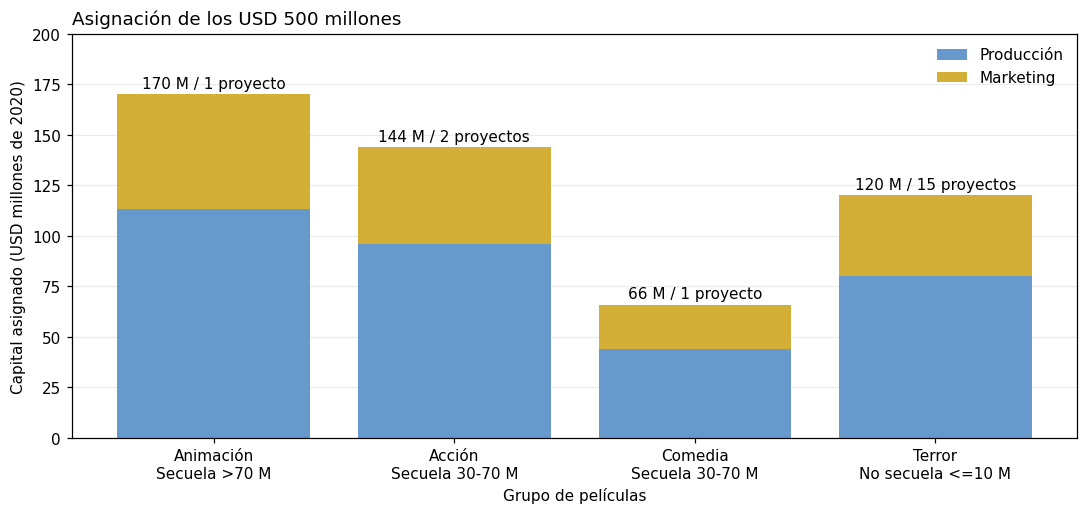

In [32]:
etiquetas_grupos = ['Animación\nSecuela >70 M', 'Acción\nSecuela 30-70 M',
                    'Comedia\nSecuela 30-70 M', 'Terror\nNo secuela <=10 M']
produccion_grupo_m = propuesta.produccion_por_proyecto_m * propuesta.proyectos
marketing_grupo_m = propuesta.marketing_por_proyecto_m * propuesta.proyectos

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(etiquetas_grupos, produccion_grupo_m, color=AZUL_CLARO_GRAFICO,
       label='Producción')
ax.bar(etiquetas_grupos, marketing_grupo_m, bottom=produccion_grupo_m,
       color=DORADO_GRAFICO, label='Marketing')
for i in range(len(propuesta)):
    fila = propuesta.iloc[i]
    palabra_proyectos = 'proyectos'
    if fila.proyectos == 1:
        palabra_proyectos = 'proyecto'
    ax.text(i, fila.asignacion_m + 3,
            f'{fila.asignacion_m:.0f} M / {fila.proyectos:.0f} {palabra_proyectos}',
            ha='center', fontsize=10)
ax.set_title('Asignación de los USD 500 millones', loc='left')
ax.set_xlabel('Grupo de películas')
ax.set_ylabel('Capital asignado (USD millones de 2020)')
ax.set_ylim(0, 200)
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '5_2_asignacion.png', dpi=150, bbox_inches='tight')
plt.show()


Observamos que una sola película de animación recibe el 34% del dinero. Terror recibe el 24%, pero repartido en 15 películas, por lo que la cantidad de proyectos no muestra por sí sola donde está concentrado el capital.

In [33]:
# Una posible distribución de los proyectos durante los tres años del caso.
cronograma = pd.DataFrame({
    'ano': ['Año 1', 'Año 2', 'Año 3'],
    'animacion': [0, 1, 0],
    'accion': [1, 0, 1],
    'comedia': [1, 0, 0],
    'terror': [5, 5, 5]
})
cronograma['proyectos'] = (
    cronograma.animacion + cronograma.accion
    + cronograma.comedia + cronograma.terror)
cronograma['capital_m'] = (
    cronograma.animacion * propuesta.iloc[0].capital_por_proyecto_m
    + cronograma.accion * propuesta.iloc[1].capital_por_proyecto_m
    + cronograma.comedia * propuesta.iloc[2].capital_por_proyecto_m
    + cronograma.terror * propuesta.iloc[3].capital_por_proyecto_m)
display(cronograma)


,ano,animacion,accion,comedia,terror,proyectos,capital_m
0,Año 1,0,1,1,5,7,178.0
1,Año 2,1,0,0,5,6,210.0
2,Año 3,0,1,0,5,6,112.0


Con este reparto colocaríamos 178, 210 y 112 millones en cada año. Es un calendario propuesto: todavía hay que conseguir los proyectos y confirmar que se puedan producir en esos plazos.

Trabajamos con dólares de 2020 para comparar con los presupuestos históricos. Los USD 500 millones del caso se tratan con ese mismo poder de compra; al llevarlo a la práctica hay que actualizar los montos. Tampoco estamos suponiendo que las películas recuperen el dinero dentro de esos tres años.

## 5.3 Retorno y riesgo del portafolio

In [34]:
N_SIMULACIONES = 10_000
SEMILLA_SIMULACION = 2026

retorno_central_pct = (
    (propuesta.asignacion_m * propuesta.roi_mediano_pct).sum() / CAPITAL_TOTAL_M)
escenario_medianas = pd.DataFrame({
    'roi_pct': [retorno_central_pct],
    'ganancia_m': [CAPITAL_TOTAL_M * retorno_central_pct / 100],
    'capital_final_m': [CAPITAL_TOTAL_M * (1 + retorno_central_pct / 100)]
})
display(escenario_medianas.round(2))


,roi_pct,ganancia_m,capital_final_m
0,21.64,108.18,608.18


Si cada grupo obtiene su mediana histórica, el portafolio gana un 21,6%, unos 108,2 millones. Este es un escenario de referencia; todavía no nos dice cuántas veces podemos perder capital.

In [35]:
generador = np.random.default_rng(SEMILLA_SIMULACION)
generador_compartido = np.random.default_rng(SEMILLA_SIMULACION + 1)
resultado_independiente_m = [0.0] * N_SIMULACIONES
resultado_compartido_m = [0.0] * N_SIMULACIONES

for i in range(len(propuesta)):
    fila = propuesta.iloc[i]
    roi_grupo = retornos_historicos[fila['grupo']]
    cantidad = int(fila['proyectos'])
    for simulacion in range(N_SIMULACIONES):
        # Cada película toma el ROI de una película histórica de su grupo.
        sorteos = generador.choice(roi_grupo, size=cantidad, replace=True)
        ganancia = fila['capital_por_proyecto_m'] * sorteos.sum()
        resultado_independiente_m[simulacion] += ganancia

    for simulacion in range(N_SIMULACIONES):
        # Todas las películas del grupo toman el mismo ROI.
        sorteo_grupo = generador_compartido.choice(roi_grupo)
        resultado_compartido_m[simulacion] += fila['asignacion_m'] * sorteo_grupo

retornos_independientes = pd.Series(resultado_independiente_m) / CAPITAL_TOTAL_M
retornos_compartidos = pd.Series(resultado_compartido_m) / CAPITAL_TOTAL_M
retornos_simulados = {
    'Proyectos independientes': retornos_independientes,
    'Resultado compartido por grupo': retornos_compartidos
}

filas_escenarios = []
for nombre, retornos in retornos_simulados.items():
    capital_final_m = CAPITAL_TOTAL_M * (1 + retornos)
    filas_escenarios.append({
        'supuesto': nombre,
        'simulaciones': len(retornos),
        'veces_con_perdida': (retornos < 0).sum(),
        'prob_perder_capital_pct': 100 * (retornos < 0).mean(),
        'roi_decil_inferior_pct': 100 * retornos.quantile(0.10),
        'roi_mediano_pct': 100 * retornos.median(),
        'capital_final_p10_m': capital_final_m.quantile(0.10),
        'capital_final_mediano_m': capital_final_m.median()
    })
escenarios = pd.DataFrame(filas_escenarios)
display(escenarios.round(2))


,supuesto,simulaciones,veces_con_perdida,prob_perder_capital_pct,roi_decil_inferior_pct,roi_mediano_pct,capital_final_p10_m,capital_final_mediano_m
0,Proyectos independientes,10000,88,0.88,45.74,113.15,728.71,1065.74
1,Resultado compartido por grupo,10000,2301,23.01,-25.81,59.28,370.95,796.38


Hicimos 10.000 simulaciones. En cada una sorteamos películas de los grupos elegidos, con posibilidad de repetirlas, y sumamos sus ganancias según el dinero que recibe cada proyecto.

Primero sorteamos cada película por separado. Después probamos que todas las películas del mismo grupo tengan el mismo resultado. Los grupos siguen sorteándose por separado; es una prueba de lo que pasa si sus resultados se mueven juntos, no una relación que hayamos medido en los datos.

La mediana de la simulación no tiene que dar igual al 21,6% anterior. Antes suponíamos que todos los grupos obtenían su mediana; acá combinamos películas con distintos resultados. Con 15 proyectos de terror hay más oportunidades de sortear un éxito grande, algo que influye mucho en el resultado.

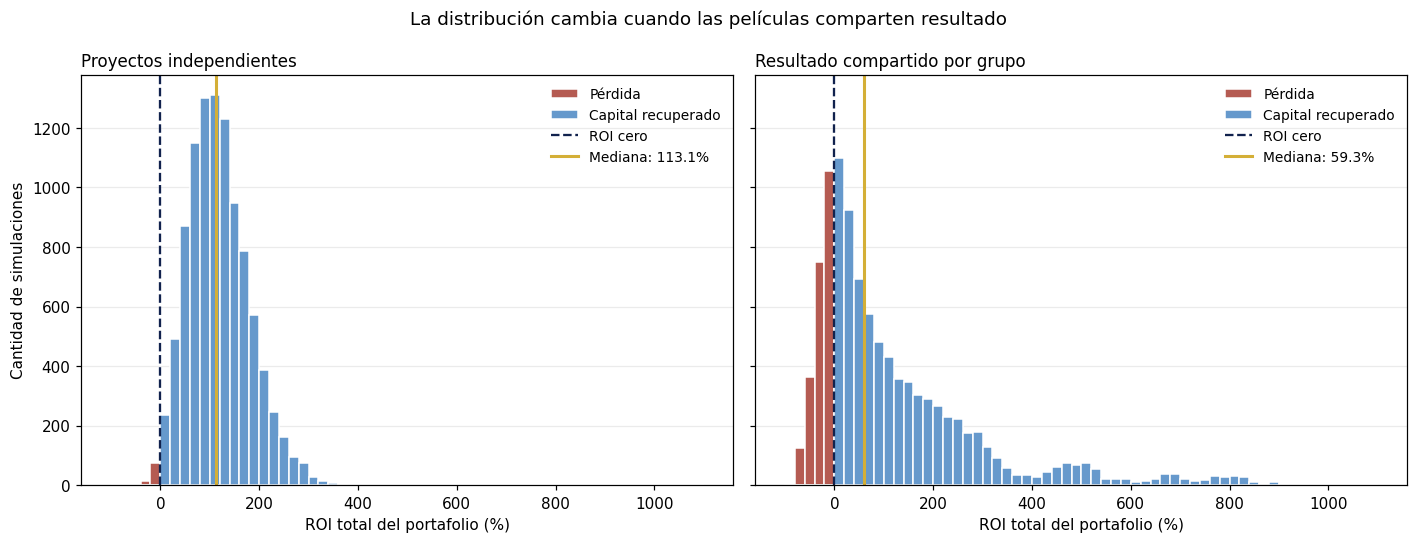

In [36]:
# Los dos histogramas usan los mismos intervalos y las mismas escalas.
todos_retornos_pct = pd.concat([
    retornos_independientes, retornos_compartidos]) * 100
intervalos_roi = np.arange(-100, todos_retornos_pct.max() + 20, 20)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for eje, (nombre, retornos) in zip(ejes, retornos_simulados.items()):
    roi_pct = retornos * 100
    eje.hist(roi_pct[roi_pct < 0], bins=intervalos_roi,
             color='#B55B52', edgecolor='white', label='Pérdida')
    eje.hist(roi_pct[roi_pct >= 0], bins=intervalos_roi,
             color=AZUL_CLARO_GRAFICO, edgecolor='white', label='Capital recuperado')
    eje.axvline(0, color=AZUL_GRAFICO, linestyle='--', label='ROI cero')
    eje.axvline(roi_pct.median(), color=DORADO_GRAFICO, linewidth=2,
                label=f'Mediana: {roi_pct.median():.1f}%')
    eje.set_title(nombre, loc='left', fontsize=11)
    eje.set_xlabel('ROI total del portafolio (%)')
    eje.legend(frameon=False, fontsize=9)
    eje.grid(axis='y', alpha=0.25)
    eje.set_axisbelow(True)
ejes[0].set_ylabel('Cantidad de simulaciones')
fig.suptitle('La distribución cambia cuando las películas comparten resultado')
fig.tight_layout()
fig.savefig(carpeta_salidas / '5_3_histogramas_simulacion.png',
            dpi=150, bbox_inches='tight')
plt.show()


Con proyectos independientes la mediana del ROI es 113,1%; cuando comparten resultado dentro del grupo baja a 59,3% y vemos más simulaciones con pérdida. Los gráficos incluyen todos los sorteos, también los éxitos del extremo derecho.

En el boxplot, la caja muestra el 50% central de los resultados, la línea interior es la mediana y los puntos son valores alejados. La línea de 500 millones permite ver cuándo el capital final queda por debajo de lo invertido.

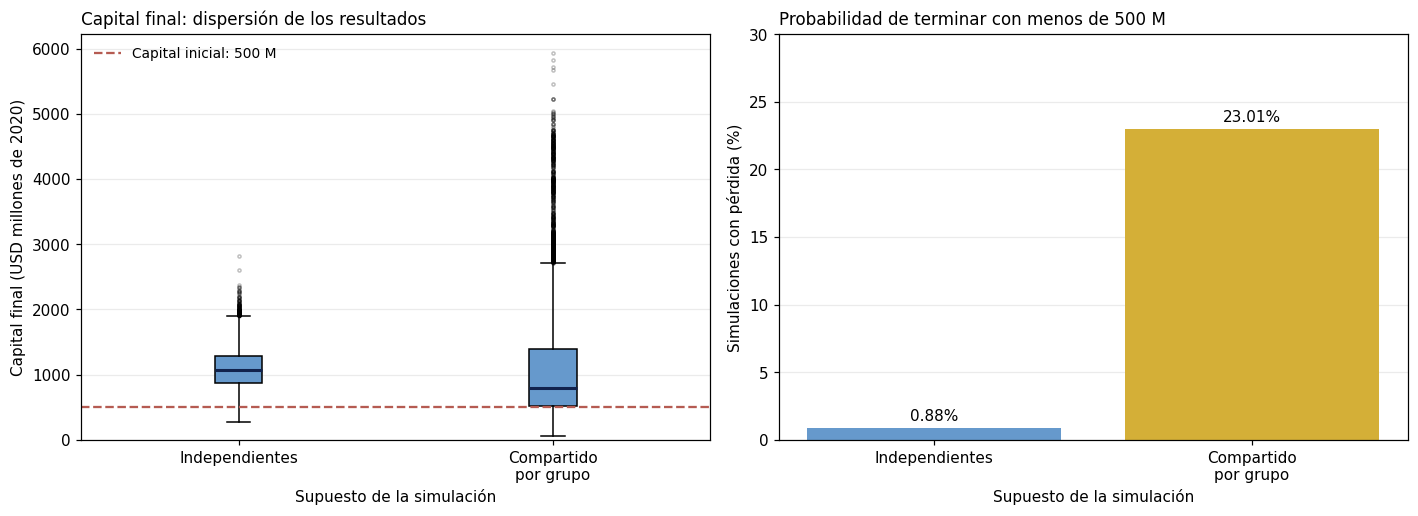

In [37]:
capitales_finales = []
for retornos in retornos_simulados.values():
    capitales_finales.append(CAPITAL_TOTAL_M * (1 + retornos))

fig, (ax_cajas, ax_riesgo) = plt.subplots(1, 2, figsize=(13, 4.8))
cajas = ax_cajas.boxplot(
    capitales_finales, patch_artist=True,
    flierprops={'marker':'o', 'markersize':2, 'alpha':0.25},
    medianprops={'color':AZUL_GRAFICO, 'linewidth':2})
for caja in cajas['boxes']:
    caja.set_facecolor(AZUL_CLARO_GRAFICO)
ax_cajas.set_xticks([1, 2])
ax_cajas.set_xticklabels(['Independientes', 'Compartido\npor grupo'])
ax_cajas.axhline(CAPITAL_TOTAL_M, color='#B55B52', linestyle='--',
                 label='Capital inicial: 500 M')
ax_cajas.set_title('Capital final: dispersión de los resultados', loc='left', fontsize=11)
ax_cajas.set_xlabel('Supuesto de la simulación')
ax_cajas.set_ylabel('Capital final (USD millones de 2020)')
ax_cajas.set_ylim(0, None)
ax_cajas.legend(frameon=False, fontsize=9)

barras = ax_riesgo.bar(['Independientes', 'Compartido\npor grupo'],
                       escenarios.prob_perder_capital_pct,
                       color=[AZUL_CLARO_GRAFICO, DORADO_GRAFICO])
ax_riesgo.bar_label(barras, fmt='%.2f%%', padding=3)
ax_riesgo.set_title('Probabilidad de terminar con menos de 500 M', loc='left', fontsize=11)
ax_riesgo.set_xlabel('Supuesto de la simulación')
ax_riesgo.set_ylabel('Simulaciones con pérdida (%)')
ax_riesgo.set_ylim(0, 30)
for eje in (ax_cajas, ax_riesgo):
    eje.grid(axis='y', alpha=0.25)
    eje.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '5_3_capital_y_riesgo.png',
            dpi=150, bbox_inches='tight')
plt.show()


La probabilidad de perder capital pasa de 0,88% a 23,01%, por lo que el primer resultado depende mucho de suponer que los proyectos son independientes. En el escenario compartido, una de cada diez simulaciones termina con unos 371 millones o menos: una pérdida de al menos 129 millones en ese 10% de los casos, no la peor pérdida posible.

## 5.4 Sensibilidad a costos y éxitos extremos

In [38]:
# Usamos la misma semilla para comparar los mismos sorteos.
resultados_sensibilidad = {}
retornos_sensibilidad = {}
for nombre, limite_roi, marketing in [
    ('Base: marketing 50%', None, 0.5),
    ('ROI limitado a 1000%', 10, 0.5),
    ('Marketing 100%, mismos proyectos', None, 1.0)
]:
    rng_sensibilidad = np.random.default_rng(SEMILLA_SIMULACION)
    ingresos_m = [0.0] * N_SIMULACIONES
    costo_m = CAPITAL_TOTAL_M * (1 + marketing) / FACTOR_COSTO_TOTAL
    for i in range(len(propuesta)):
        fila = propuesta.iloc[i]
        cantidad = int(fila['proyectos'])
        for simulacion in range(N_SIMULACIONES):
            sorteos = rng_sensibilidad.choice(
                retornos_historicos[fila['grupo']], size=cantidad, replace=True)
            retornos = pd.Series(sorteos)
            if limite_roi is not None:
                retornos = retornos.clip(upper=limite_roi)
            ingreso = fila['capital_por_proyecto_m'] * (1 + retornos).sum()
            ingresos_m[simulacion] += ingreso
    roi_escenario = pd.Series(ingresos_m) / costo_m - 1
    retornos_sensibilidad[nombre] = roi_escenario
    resultados_sensibilidad[nombre] = {
        'capital_necesario_m': costo_m,
        'capital_adicional_m': costo_m - CAPITAL_TOTAL_M,
        'roi_mediano_pct': 100 * roi_escenario.median(),
        'prob_perder_pct': 100 * (roi_escenario < 0).mean()
    }
tabla_sensibilidad = pd.DataFrame(resultados_sensibilidad).T
display(tabla_sensibilidad.round(2))


,capital_necesario_m,capital_adicional_m,roi_mediano_pct,prob_perder_pct
Base: marketing 50%,500.00,0.00,113.15,0.88
ROI limitado a 1000%,500.00,0.00,85.45,1.32
"Marketing 100%, mismos proyectos",666.67,166.67,59.86,6.07


Al limitar cada ROI histórico a un máximo de 1000%, la mediana del portafolio baja de 113,1% a 85,5%. Es una prueba para ver cuánto pesan los éxitos extremos; no estamos diciendo que esos retornos sean errores ni cambiando el historial original.

Si marketing pasa del 50% al 100% de producción y los ingresos no cambian, los mismos proyectos cuestan 666,7 millones. Ese escenario necesita 166,7 millones adicionales y no entra en la propuesta de 500 millones.

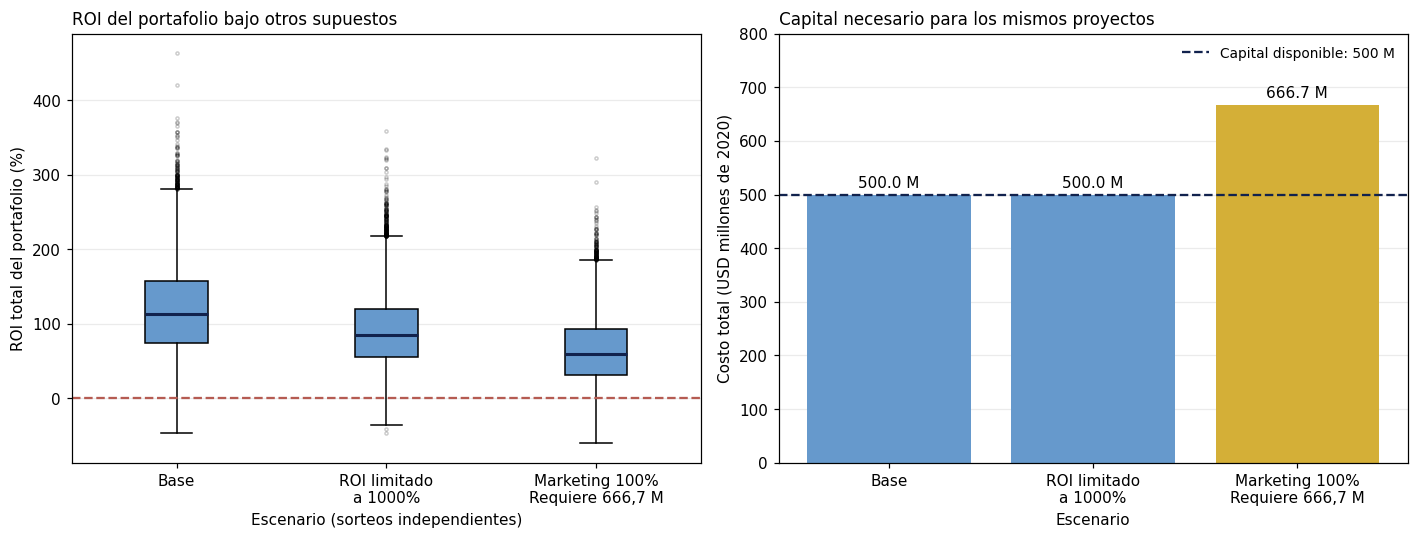

In [39]:
etiquetas_sensibilidad = ['Base', 'ROI limitado\na 1000%', 'Marketing 100%\nRequiere 666,7 M']
datos_cajas_sensibilidad = []
for retornos in retornos_sensibilidad.values():
    datos_cajas_sensibilidad.append(retornos * 100)

fig, (ax_roi, ax_costo) = plt.subplots(1, 2, figsize=(13, 5))
cajas = ax_roi.boxplot(
    datos_cajas_sensibilidad, patch_artist=True,
    flierprops={'marker':'o', 'markersize':2, 'alpha':0.2},
    medianprops={'color':AZUL_GRAFICO, 'linewidth':2})
for caja in cajas['boxes']:
    caja.set_facecolor(AZUL_CLARO_GRAFICO)
ax_roi.set_xticks([1, 2, 3])
ax_roi.set_xticklabels(etiquetas_sensibilidad)
ax_roi.axhline(0, color='#B55B52', linestyle='--')
ax_roi.set_title('ROI del portafolio bajo otros supuestos', loc='left', fontsize=11)
ax_roi.set_xlabel('Escenario (sorteos independientes)')
ax_roi.set_ylabel('ROI total del portafolio (%)')

barras = ax_costo.bar(etiquetas_sensibilidad,
                      tabla_sensibilidad.capital_necesario_m,
                      color=[AZUL_CLARO_GRAFICO, AZUL_CLARO_GRAFICO, DORADO_GRAFICO])
ax_costo.bar_label(barras, fmt='%.1f M', padding=3)
ax_costo.axhline(CAPITAL_TOTAL_M, color=AZUL_GRAFICO, linestyle='--',
                 label='Capital disponible: 500 M')
ax_costo.set_title('Capital necesario para los mismos proyectos', loc='left', fontsize=11)
ax_costo.set_xlabel('Escenario')
ax_costo.set_ylabel('Costo total (USD millones de 2020)')
ax_costo.set_ylim(0, 800)
ax_costo.legend(frameon=False, fontsize=9)
for eje in (ax_roi, ax_costo):
    eje.grid(axis='y', alpha=0.25)
    eje.set_axisbelow(True)
fig.tight_layout()
fig.savefig(carpeta_salidas / '5_4_sensibilidad_simulacion.png',
            dpi=150, bbox_inches='tight')
plt.show()


Observamos que los retornos bajan cuando limitamos los grandes éxitos o aumentamos el marketing. La última barra supera el capital disponible, por lo que para hacer esos mismos proyectos habría que conseguir más capital o reducir el plan.

## 5.5 Dónde no invertir y limitaciones

In [40]:
no_invertir = []
for genero in ['Drama', 'Policial']:
    grupo = portafolio_base.loc[
        (portafolio_base.genero == genero)
        & (portafolio_base.tramo_presupuesto == '30-70')
        & (portafolio_base.es_secuela == 'No')]
    no_invertir.append({
        'grupo':genero + ', 30-70 M, no secuela',
        'peliculas_historicas':len(grupo),
        'roi_mediano_pct':100 * grupo.roi_salas_estimado.median(),
        'perdida_roi_pct':100 * grupo.perdida_roi.mean(),
        'fracaso_pct':100 * grupo.fracaso_2_5x.mean()
    })

print('Grupos que evitaríamos inicialmente:')
display(pd.DataFrame(no_invertir).round(1))

# Movemos los cortes para ver cuánto depende de ellos la tesis.
filas_sensibilidad_cortes = []
for corte_bajo, corte_medio, corte_alto in [(8,25,65), (10,30,70),
                                             (12,35,75)]:
    terror_bajo = portafolio_base.loc[
        (portafolio_base.genero == 'Terror')
        & (portafolio_base.es_secuela == 'No')
        & (portafolio_base.presupuesto_millones <= corte_bajo)]
    accion_media = portafolio_base.loc[
        (portafolio_base.genero == 'Acción')
        & (portafolio_base.es_secuela == 'Si')
        & (portafolio_base.presupuesto_millones > corte_medio)
        & (portafolio_base.presupuesto_millones <= corte_alto)]
    filas_sensibilidad_cortes.append({
        'cortes_millones':f'{corte_bajo}/{corte_medio}/{corte_alto}',
        'terror_n':len(terror_bajo),
        'terror_roi_mediano_pct':100 * terror_bajo.roi_salas_estimado.median(),
        'accion_n':len(accion_media),
        'accion_roi_mediano_pct':100 * accion_media.roi_salas_estimado.median()
    })

print('Sensibilidad de dos grupos a los cortes de presupuesto:')
display(pd.DataFrame(filas_sensibilidad_cortes).round(1))


Grupos que evitaríamos inicialmente:
Sensibilidad de dos grupos a los cortes de presupuesto:


,grupo,peliculas_historicas,roi_mediano_pct,perdida_roi_pct,fracaso_pct
0,"Drama, 30-70 M, no secuela",253,-61.6,75.1,68.4
1,"Policial, 30-70 M, no secuela",121,-60.0,79.3,75.2


,cortes_millones,terror_n,terror_roi_mediano_pct,accion_n,accion_roi_mediano_pct
0,8/25/65,56,80.6,73,2.4
1,10/30/70,66,44.6,80,-8.6
2,12/35/75,80,27.8,78,-11.1


No priorizaríamos drama y policial no secuela de 30 a 70 millones. Sus medianas de ROI son aproximadamente -61,6% y -60,0%, y la mayoría no llega a la regla de 2,5x. Esto aplica a esos grupos concretos, no a todas las películas de esos géneros.

También movimos los cortes de presupuesto. Los resultados de terror y acción cambian según el tramo elegido, por lo que esos límites son parte de la decisión y hay que revisarlos al evaluar proyectos concretos.

Limitaciones:

- Los presupuestos faltantes no se distribuyen igual entre géneros, países y décadas. Solo podemos calcular ROI donde tenemos los datos necesarios.
- El filtro de presupuesto deja fuera valores dudosos, pero también películas pequeñas reales.
- Elegimos los grupos y los evaluamos con la misma historia. No probamos cómo habrían funcionado con películas nuevas.
- Sortear de la historia supone que esos resultados pueden repetirse. Tener 10.000 simulaciones no agrega películas nuevas a los 33-80 casos de cada grupo.
- El escenario compartido prueba dependencia dentro de cada grupo. No mide lo que pasa si todos los grupos caen juntos.
- No conocemos el marketing real de cada película, los contratos, los ingresos de streaming ni los tiempos de cobro. El ROI de salas es una estimación del proyecto, no una rentabilidad contractual del fondo ni una tasa anual.

La propuesta cumple con los cuatro grupos, los 500 millones y la cantidad de proyectos. Antes de invertir revisaríamos especialmente el peso de acción y comedia, la concentración en una sola película de animación y si podemos conseguir 15 proyectos de terror comparables. La simulación ayuda a ver esos riesgos, pero no garantiza los resultados.